Student Name: Saksham Bajpai

GenAi use: For this assignment GenAi has been used to clarify concepts, theories, ideas, etc., discussed in class and debug codes.


In [ ]:

install.packages(c("tidyverse", "data.table", "lubridate"))

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [ ]:
# Load libraries
library(tidyverse)
library(data.table)
library(lubridate)

# Load the data
crash_data <- fread("vic_road_crash_data.csv")

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.1     ✔ stringr   1.5.2
✔ ggplot2   4.0.0     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.1.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors

Attaching package: ‘data.table’


The following objects are masked from ‘package:lubridate’:

    hour, isoweek, mday, minute, month, quarter, second, wday, week,
    yday, year


The following objects are masked from ‘package:dplyr’:

    between, first, last


The following object is masked from ‘package:purrr’:

    transpose




In [ ]:
# Creating New Dataframe
time_series_df <- crash_data %>%

  # 1. Fix column names
  select(
    ACCIDENT_NO,
    ACCIDENT_DATE,
    ACCIDENT_TIME,
    SEVERITY
  ) %>%

  # 2. Create the datetime object
  mutate(
    datetime = ymd_hms(paste(ACCIDENT_DATE, ACCIDENT_TIME))
  ) %>%

  # 3. Handle missing values
  #    Remove rows with no date OR no severity
  filter(
    !is.na(datetime) & !is.na(SEVERITY) & SEVERITY != ""
  )

Warning message:
“There was 1 warning in `mutate()`.
ℹ In argument: `datetime = ymd_hms(paste(ACCIDENT_DATE, ACCIDENT_TIME))`.
Caused by warning:
! All formats failed to parse. No formats found.”


In [ ]:
# Count total crashes per day
crashes_by_day <- time_series_df %>%
  mutate(date_only = floor_date(datetime, "day")) %>%
  group_by(date_only) %>%
  summarise(crash_count = n())

In [ ]:

crash_data <- fread("vic_road_crash_data.csv")


cat("Sample ACCIDENT_DATE formats: ---\n")
print(head(crash_data$ACCIDENT_DATE))

cat("\n Sample ACCIDENT_TIME formats: ---\n")
print(head(crash_data$ACCIDENT_TIME))

Sample ACCIDENT_DATE formats: ---
[1] "5/19/2012"  "06-06-2023" "4/19/2024"  "4/30/2016"  "1/21/2022" 
[6] "1/17/2023" 

 Sample ACCIDENT_TIME formats: ---
[1] "11:30:00 PM" "10:14:00 PM" "2:10:00 AM"  "11:50:00 PM" "10:45:00 PM"
[6] "3:56:00 PM" 


Visualisation 1: Time series visualisation to examine trends in road crashes

`summarise()` has grouped output by 'date_only'. You can override using the
`.groups` argument.


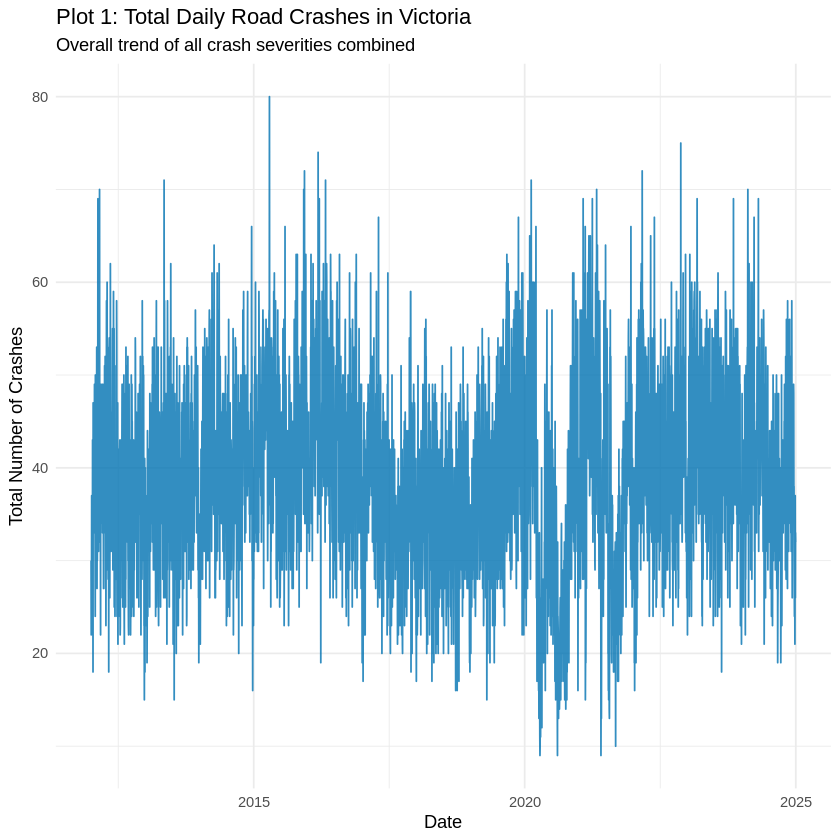

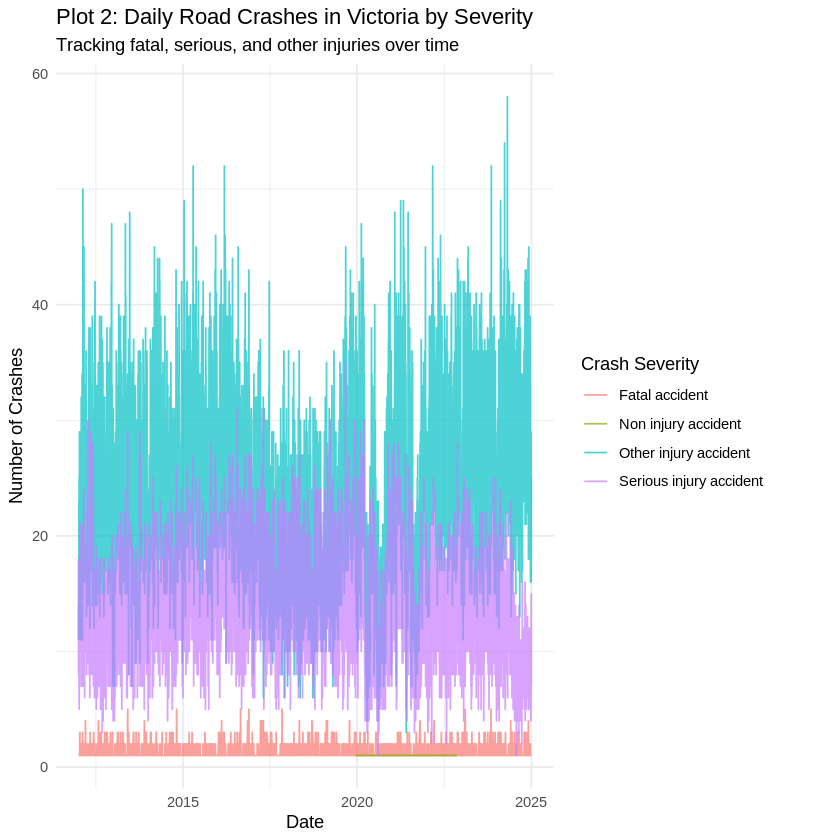

In [ ]:
# install.packages(c("tidyverse", "data.table", "lubridate"))

library(tidyverse)
library(data.table)
library(lubridate)

# Load the data
crash_data <- fread("vic_road_crash_data.csv")


# Clean and Transform -


time_series_df <- crash_data %>%

  # 1. Fix column names
  select(
    ACCIDENT_NO,
    ACCIDENT_DATE,
    ACCIDENT_TIME,
    SEVERITY
  ) %>%



mutate(
    datetime = mdy_hms(paste(ACCIDENT_DATE, ACCIDENT_TIME))
  ) %>%

  #
  # Remove rows with no date OR no severity
  filter(
    !is.na(datetime) & !is.na(SEVERITY) & SEVERITY != ""
  )


#  Aggregate (Total Crashes)
# Count total crashes per day
crashes_by_day <- time_series_df %>%
  mutate(date_only = floor_date(datetime, "day")) %>%
  group_by(date_only) %>%
  summarise(crash_count = n())




# Creating time series plot
plot1 <- ggplot(crashes_by_day, aes(x = date_only, y = crash_count)) +
  geom_line(color = "#0072B2", alpha = 0.8) +
  labs(
    title = "Plot 1: Total Daily Road Crashes in Victoria",
    subtitle = "Overall trend of all crash severities combined",
    x = "Date",
    y = "Total Number of Crashes"
  ) +
  theme_minimal()

# This command will show the plot
print(plot1)
crashes_by_day_severity <- time_series_df %>%
  mutate(date_only = floor_date(datetime, "day")) %>%

  # Group by both date AND severity
  group_by(date_only, SEVERITY) %>%

  summarise(crash_count = n())


#  Visualize (Plot 2: By Severity)
# Create the second time series plot
plot2 <- ggplot(crashes_by_day_severity, aes(x = date_only, y = crash_count, color = SEVERITY)) +
  geom_line(alpha = 0.7) +
  labs(
    title = "Plot 2: Daily Road Crashes in Victoria by Severity",
    subtitle = "Tracking fatal, serious, and other injuries over time",
    x = "Date",
    y = "Number of Crashes",
    color = "Crash Severity"
  ) +
  theme_minimal()


print(plot2)

Viz 1.1 Assessing the trends (W Pattern) around the Pandemic timeline


Attaching package: ‘scales’


The following object is masked from ‘package:purrr’:

    discard


The following object is masked from ‘package:readr’:

    col_factor




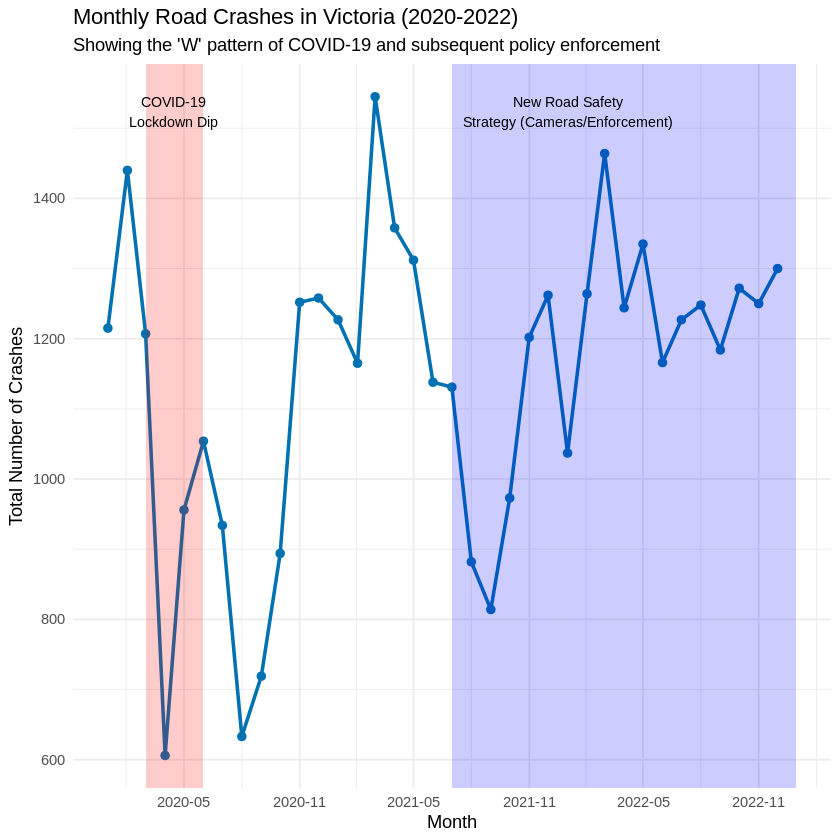

In [ ]:
library(tidyverse)
library(lubridate)
library(scales) # For date formatting



# 1. Aggregate crashes by Month, filtering for 2020-2022
monthly_crashes_2020_2022 <- time_series_df %>%


  filter(datetime >= ymd("2020-01-01") & datetime <= ymd("2022-12-31")) %>%


  mutate(month = floor_date(datetime, "month")) %>%


  group_by(month) %>%
  summarise(crash_count = n())

# 2. Build the plot
plot_1_trend <- ggplot(monthly_crashes_2020_2022, aes(x = month, y = crash_count)) +
  geom_line(color = "#0072B2", linewidth = 1) +
  geom_point(color = "#0072B2", size = 2) +


  annotate(
    "rect",
    xmin = ymd("2020-03-01"), xmax = ymd("2020-06-01"),
    ymin = -Inf, ymax = Inf,
    fill = "red", alpha = 0.2
  ) +
  annotate(
    "text", x = ymd("2020-04-15"), y = max(monthly_crashes_2020_2022$crash_count),
    label = "COVID-19\nLockdown Dip", vjust = 1, size = 3
  ) +

  annotate(
    "rect",
    xmin = ymd("2021-07-01"), xmax = ymd("2022-12-31"),
    ymin = -Inf, ymax = Inf,
    fill = "blue", alpha = 0.2
  ) +
  annotate(
    "text", x = ymd("2022-01-01"), y = max(monthly_crashes_2020_2022$crash_count),
    label = "New Road Safety\nStrategy (Cameras/Enforcement)", vjust = 1, size = 3
  ) +

  scale_x_date(labels = date_format("%Y-%m"), breaks = "6 months") +
  labs(
    title = "Monthly Road Crashes in Victoria (2020-2022)",
    subtitle = "Showing the 'W' pattern of COVID-19 and subsequent policy enforcement",
    x = "Month",
    y = "Total Number of Crashes"
  ) +
  theme_minimal()

# 3. Print the plot
print(plot_1_trend)

The plot revealed a clear "W" pattern. The first dip (early 2020) was due to Pandemic Lockdown. The second dip (2021-2022) correlates with a policy : the rollout of the Victorian Road Safety Strategy 2021-2030, which included new AI-powered speed and mobile phone cameras.

Visualisation 2: Geographic distribution of road crashes across
different regions in Victoria.

In [ ]:
# Install the ggmap package from its developer's source
install.packages("devtools")
devtools::install_github("dkahle/ggmap")

# Also install these, which ggmap uses
install.packages(c("sf", "rnaturalearth"))

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)




bitops (NA -> 1.0-9 ) [CRAN]
jpeg   (NA -> 0.1-11) [CRAN]
plyr   (NA -> 1.8.9 ) [CRAN]
png    (NA -> 0.1-8 ) [CRAN]


Installing 4 packages: bitops, jpeg, plyr, png

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



── R CMD build ─────────────────────────────────────────────────────────────────
* checking for file ‘/tmp/RtmpmCgdlK/remotes18e6a3ddf4d/dkahle-ggmap-a0fed5c/DESCRIPTION’ ... OK
* preparing ‘ggmap’:
* checking DESCRIPTION meta-information ... OK
* checking for LF line-endings in source and make files and shell scripts
* checking for empty or unneeded directories
Removed empty directory ‘ggmap/.github’
* building ‘ggmap_4.0.2.900.tar.gz’



Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘proxy’, ‘e1071’, ‘wk’, ‘classInt’, ‘s2’, ‘units’, ‘terra’


Warning message in install.packages(c("sf", "rnaturalearth")):
“installation of package ‘s2’ had non-zero exit status”
Warning message in install.packages(c("sf", "rnaturalearth")):
“installation of package ‘sf’ had non-zero exit status”
Warning message in install.packages(c("sf", "rnaturalearth")):
“installation of package ‘rnaturalearth’ had non-zero exit status”


In [ ]:
library(tidyverse)
library(data.table)

# 1. Load the data
crash_data <- fread("vic_road_crash_data.csv")

# 2. Summary of the coordinate columns T
cat("--- Summary of LATITUDE Column: ---\n")
print(summary(crash_data$LATITUDE))

cat("\n--- Summary of LONGITUDE Column: ---\n")
print(summary(crash_data$LONGITUDE))

--- Summary of LATITUDE Column: ---
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 -39.03  -37.96  -37.82  -37.72  -37.70  -34.12 

--- Summary of LONGITUDE Column: ---
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  141.0   144.8   145.0   145.0   145.2   149.8 


ℹ <https://maps.googleapis.com/maps/api/staticmap?center=Victoria,%20Australia&zoom=6&size=640x640&scale=2&maptype=roadmap&key=xxx-KQQ>

ℹ <https://maps.googleapis.com/maps/api/geocode/json?address=Victoria,+Australia&key=xxx-KQQ>



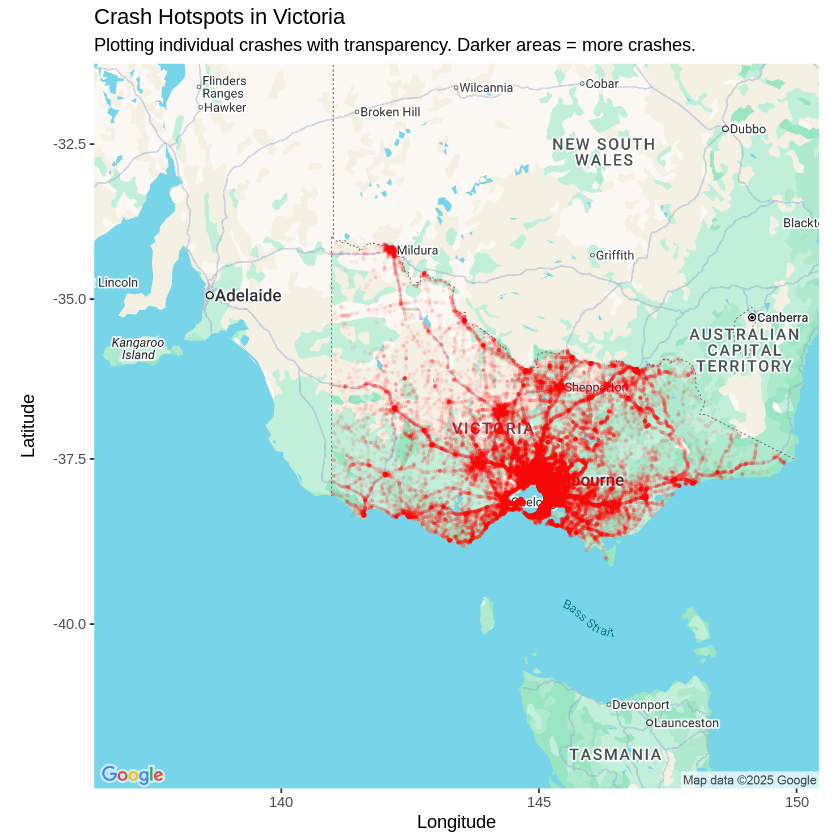

In [ ]:

library(tidyverse)
library(data.table)
library(ggmap)



register_google(key = Sys.getenv("GOOGLE_MAPS_API_KEY"))


crash_data <- fread("vic_road_crash_data.csv")


coords_df <- crash_data %>%
  select(LATITUDE, LONGITUDE) %>%
  filter(
    !is.na(LATITUDE) & !is.na(LONGITUDE) &
    LATITUDE > -39.2 & LATITUDE < -33.9 &
    LONGITUDE > 140.9 & LONGITUDE < 150.0

  )

melbourne_map <- get_googlemap(
  center = "Victoria, Australia",
  zoom = 6,
  maptype = "roadmap"
)

ggmap(melbourne_map) +


  geom_point(
    data = coords_df,
    aes(x = LONGITUDE, y = LATITUDE),
    color = "red",
    size = 0.5,
    alpha = 0.05
  ) +

  labs(
    title = "Crash Hotspots in Victoria",
    subtitle = "Plotting individual crashes with transparency. Darker areas = more crashes.",
    x = "Longitude",
    y = "Latitude"
  ) +
  theme(legend.position = "none")

Sorted bar Chart of Top 20 Crashes by LGA in Victoria, so we can identify our Top 10 LGA's


Attaching package: ‘scales’


The following object is masked from ‘package:purrr’:

    discard


The following object is masked from ‘package:readr’:

    col_factor




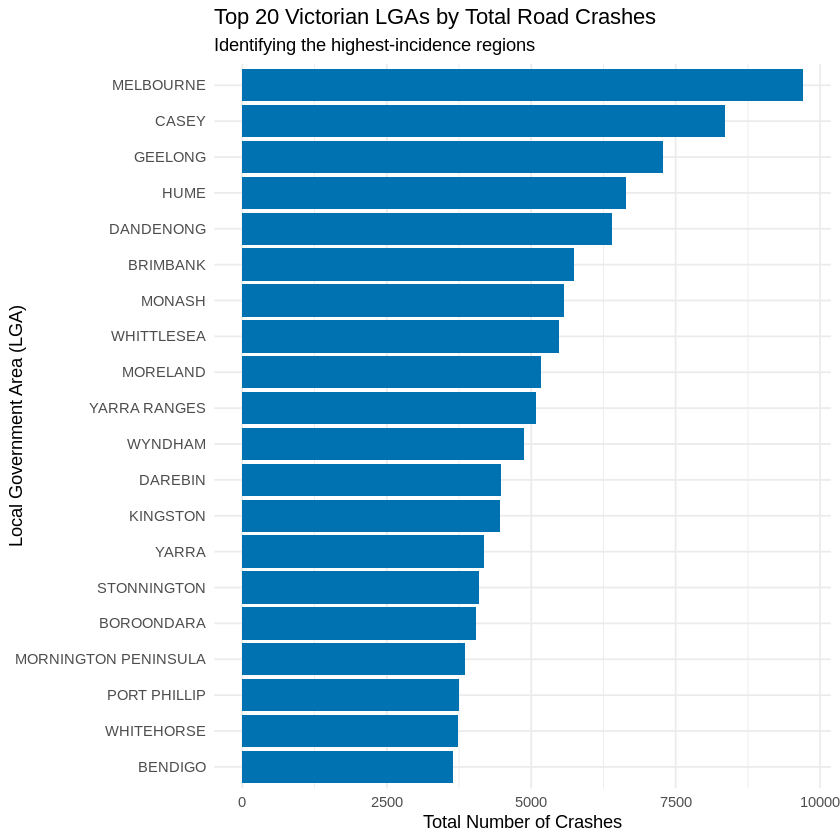

In [ ]:
library(tidyverse)
library(data.table)
library(scales)


crash_data <- fread("vic_road_crash_data.csv")


crashes_by_lga <- crash_data %>%

  # Select only the columns we need
  select(
    ACCIDENT_NO ,
    LGA_NAME
  ) %>%

  # Clean missing LGA names
  filter(!is.na(LGA_NAME) & LGA_NAME != "") %>%

  # Group by the LGA name and count the crashes
  group_by(LGA_NAME) %>%
  summarise(crash_count = n()) %>%


  arrange(desc(crash_count))

#Top 20 LGAs
top_20_lga <- head(crashes_by_lga, 20)


# We use reorder(LGA_NAME, crash_count) to make the bar chart sorted
ggplot(top_20_lga, aes(x = crash_count, y = reorder(LGA_NAME, crash_count))) +
  geom_col(fill = "#0072B2") +
  labs(
    title = "Top 20 Victorian LGAs by Total Road Crashes",
    subtitle = "Identifying the highest-incidence regions",
    x = "Total Number of Crashes",
    y = "Local Government Area (LGA)"
  ) +
  theme_minimal()

Fix: Hard code the latitude/Longitude coordinates

In [ ]:
library(tidyverse)
library(data.table)
library(stringr)


person_data <- fread("cleaned_person.csv")
crash_data <- fread("vic_road_crash_data.csv")


clean_crash <- crash_data %>%
  mutate(ACCIDENT_NO = toupper(str_trim(ACCIDENT_NO))) %>%

  select(ACCIDENT_NO, LGA_NAME, LATITUDE, LONGITUDE) %>%
  #Fix the coordinates
  filter(
    !is.na(LATITUDE) & !is.na(LONGITUDE) &
    LATITUDE > -39.2 & LATITUDE < -33.9 &
    LONGITUDE > 140.9 & LONGITUDE < 150.0
  )

clean_person <- person_data %>%
  mutate(ACCIDENT_NO = toupper(str_trim(ACCIDENT_NO))) %>%
  # We only need the key and the severity
  select(ACCIDENT_NO, INJ_LEVEL_DESC) %>%
  filter(!is.na(INJ_LEVEL_DESC) & INJ_LEVEL_DESC != "")


master_map_df <- inner_join(
  clean_crash,
  clean_person,
  by = "ACCIDENT_NO"
)


cat("--- Our master_map_df is ready --- \n")
print(head(master_map_df))
cat(paste("\nTotal rows in master_map_df:", nrow(master_map_df), "\n"))

--- Our master_map_df is ready --- 
    ACCIDENT_NO LGA_NAME  LATITUDE LONGITUDE INJ_LEVEL_DESC
         <char>   <char>     <num>     <num>         <char>
1: T20120011778    CASEY -38.11688  145.3125   Other injury
2: T20120011778    CASEY -38.11688  145.3125    Not injured
3: T20120011778    CASEY -38.11688  145.3125 Serious injury
4: T20120011778    CASEY -38.11688  145.3125    Not injured
5: T20120011778    CASEY -38.11688  145.3125    Not injured
6: T20120011778    CASEY -38.11688  145.3125    Not injured

Total rows in master_map_df: 433657 


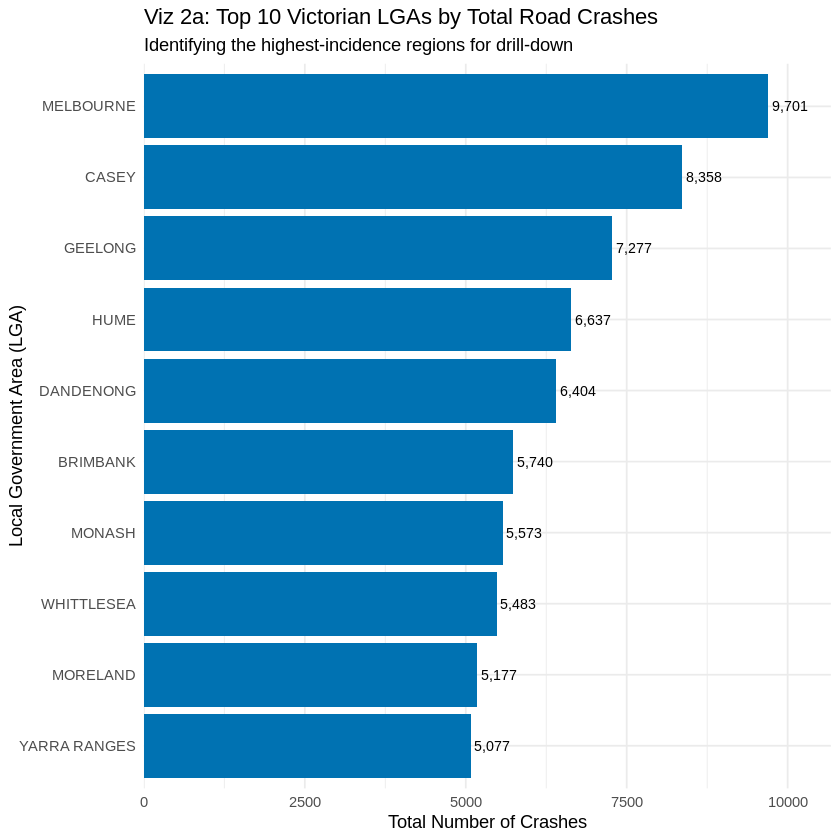

In [ ]:
library(tidyverse)
library(data.table)
library(scales)

# --- Viz 2a: Step 1 ---
# We use the original crash_data to get the total counts

crash_data <- fread("vic_road_crash_data.csv")

# 1. Create a dataframe of crash counts by LGA
crashes_by_lga <- crash_data %>%
  select(
    ACCIDENT_NO, LGA_NAME
  ) %>%
  filter(!is.na(LGA_NAME) & LGA_NAME != "") %>%
  group_by(LGA_NAME) %>%
  summarise(crash_count = n()) %>%
  arrange(desc(crash_count))

# 2. Get *only* the Top 10 LGAs
top_10_lga <- head(crashes_by_lga, 10)

# --- Viz 2a: Step 2 ---
# Plot the Top 10
# We use reorder(LGA_NAME, crash_count) to make the bar chart sorted
ggplot(top_10_lga, aes(x = crash_count, y = reorder(LGA_NAME, crash_count))) +
  geom_col(fill = "#0072B2") +
  geom_text(aes(label = comma(crash_count)), hjust = -0.1, size = 3) + # Add count labels
  scale_x_continuous(expand = expansion(mult = c(0, 0.1))) + # Give labels space
  labs(
    title = "Viz 2a: Top 10 Victorian LGAs by Total Road Crashes",
    subtitle = "Identifying the highest-incidence regions for drill-down",
    x = "Total Number of Crashes",
    y = "Local Government Area (LGA)"
  ) +
  theme_minimal()

Visualising crashes for Top-10 LGA's with crashes in Victoria


ℹ <https://maps.googleapis.com/maps/api/staticmap?center=MELBOURNE,%20Victoria,%20Australia&zoom=12&size=640x640&scale=2&maptype=roadmap&key=xxx-KQQ>

ℹ <https://maps.googleapis.com/maps/api/geocode/json?address=MELBOURNE,+Victoria,+Australia&key=xxx-KQQ>

ℹ <https://maps.googleapis.com/maps/api/staticmap?center=CASEY,%20Victoria,%20Australia&zoom=12&size=640x640&scale=2&maptype=roadmap&key=xxx-KQQ>

ℹ <https://maps.googleapis.com/maps/api/geocode/json?address=CASEY,+Victoria,+Australia&key=xxx-KQQ>

Warning message:
“Removed 7184 rows containing missing values or values outside the scale range
(`geom_point()`).”


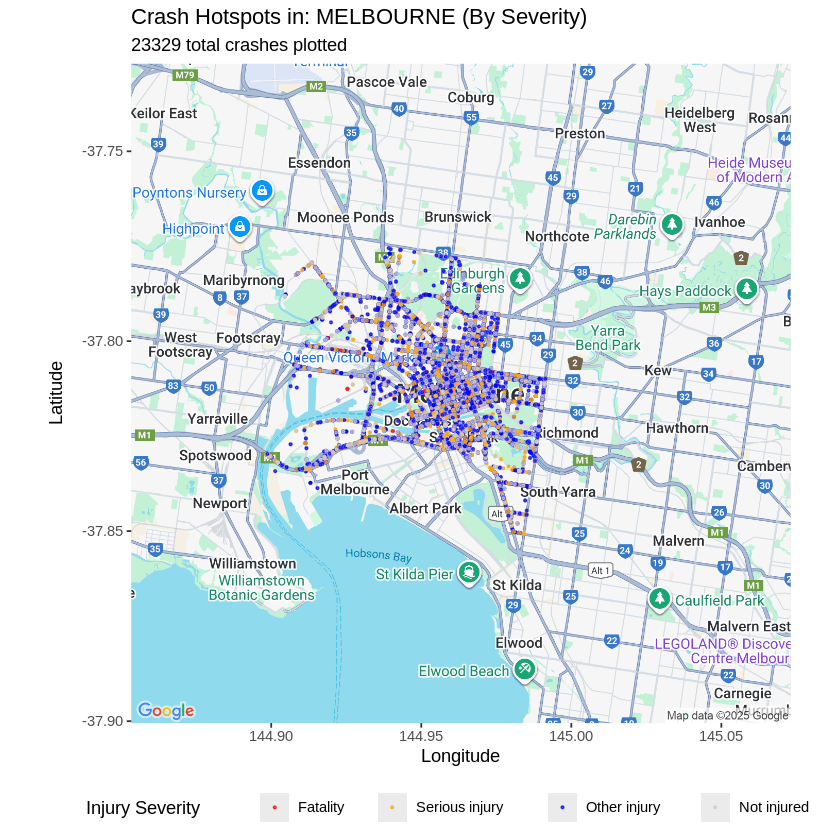

ℹ <https://maps.googleapis.com/maps/api/staticmap?center=GEELONG,%20Victoria,%20Australia&zoom=12&size=640x640&scale=2&maptype=roadmap&key=xxx-KQQ>

ℹ <https://maps.googleapis.com/maps/api/geocode/json?address=GEELONG,+Victoria,+Australia&key=xxx-KQQ>

Warning message:
“Removed 3493 rows containing missing values or values outside the scale range
(`geom_point()`).”


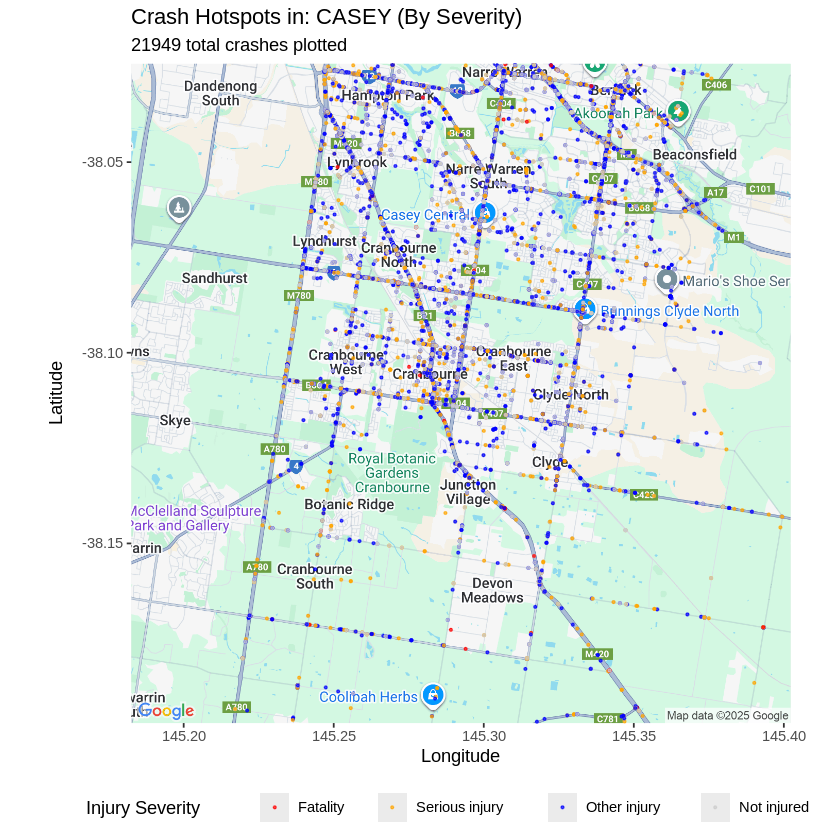

ℹ <https://maps.googleapis.com/maps/api/staticmap?center=HUME,%20Victoria,%20Australia&zoom=12&size=640x640&scale=2&maptype=roadmap&key=xxx-KQQ>

ℹ <https://maps.googleapis.com/maps/api/geocode/json?address=HUME,+Victoria,+Australia&key=xxx-KQQ>

Warning message:
“Removed 7349 rows containing missing values or values outside the scale range
(`geom_point()`).”


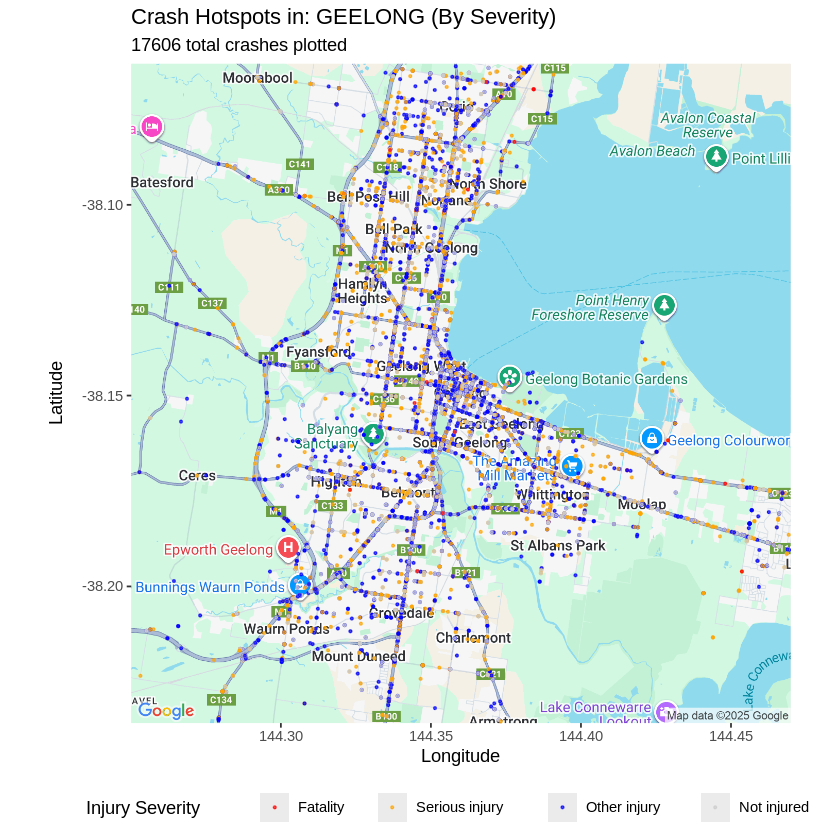

ℹ <https://maps.googleapis.com/maps/api/staticmap?center=DANDENONG,%20Victoria,%20Australia&zoom=12&size=640x640&scale=2&maptype=roadmap&key=xxx-KQQ>

ℹ <https://maps.googleapis.com/maps/api/geocode/json?address=DANDENONG,+Victoria,+Australia&key=xxx-KQQ>

Warning message:
“Removed 296 rows containing missing values or values outside the scale range
(`geom_point()`).”


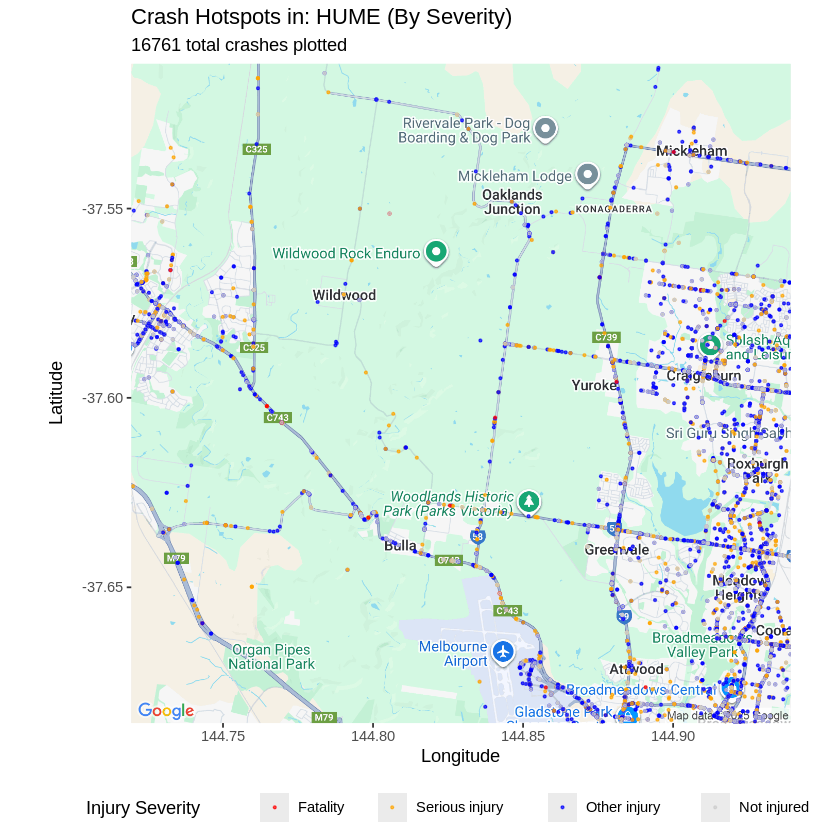

ℹ <https://maps.googleapis.com/maps/api/staticmap?center=BRIMBANK,%20Victoria,%20Australia&zoom=12&size=640x640&scale=2&maptype=roadmap&key=xxx-KQQ>

ℹ <https://maps.googleapis.com/maps/api/geocode/json?address=BRIMBANK,+Victoria,+Australia&key=xxx-KQQ>

Warning message:
“Removed 28 rows containing missing values or values outside the scale range
(`geom_point()`).”


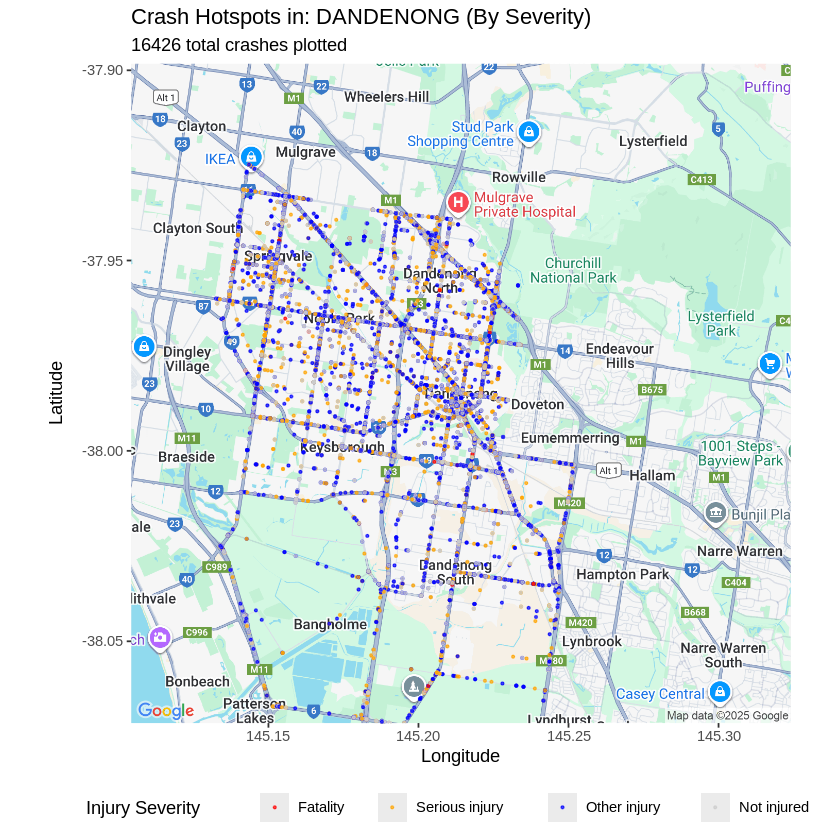

ℹ <https://maps.googleapis.com/maps/api/staticmap?center=MONASH,%20Victoria,%20Australia&zoom=12&size=640x640&scale=2&maptype=roadmap&key=xxx-KQQ>

ℹ <https://maps.googleapis.com/maps/api/geocode/json?address=MONASH,+Victoria,+Australia&key=xxx-KQQ>



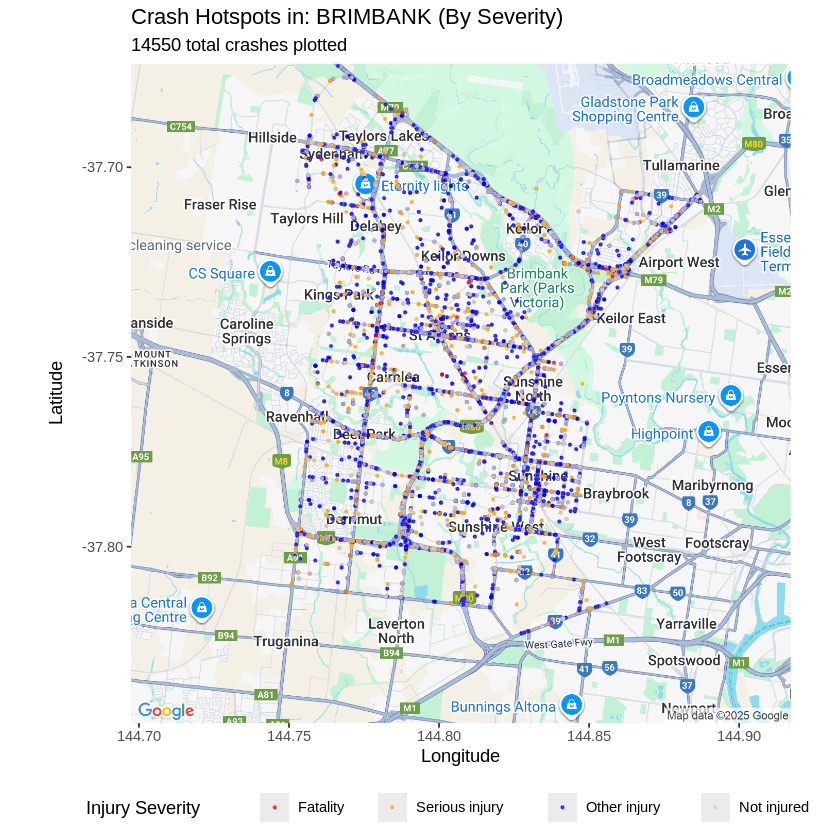

ℹ <https://maps.googleapis.com/maps/api/staticmap?center=WHITTLESEA,%20Victoria,%20Australia&zoom=12&size=640x640&scale=2&maptype=roadmap&key=xxx-KQQ>

ℹ <https://maps.googleapis.com/maps/api/geocode/json?address=WHITTLESEA,+Victoria,+Australia&key=xxx-KQQ>

Warning message:
“Removed 12313 rows containing missing values or values outside the scale range
(`geom_point()`).”


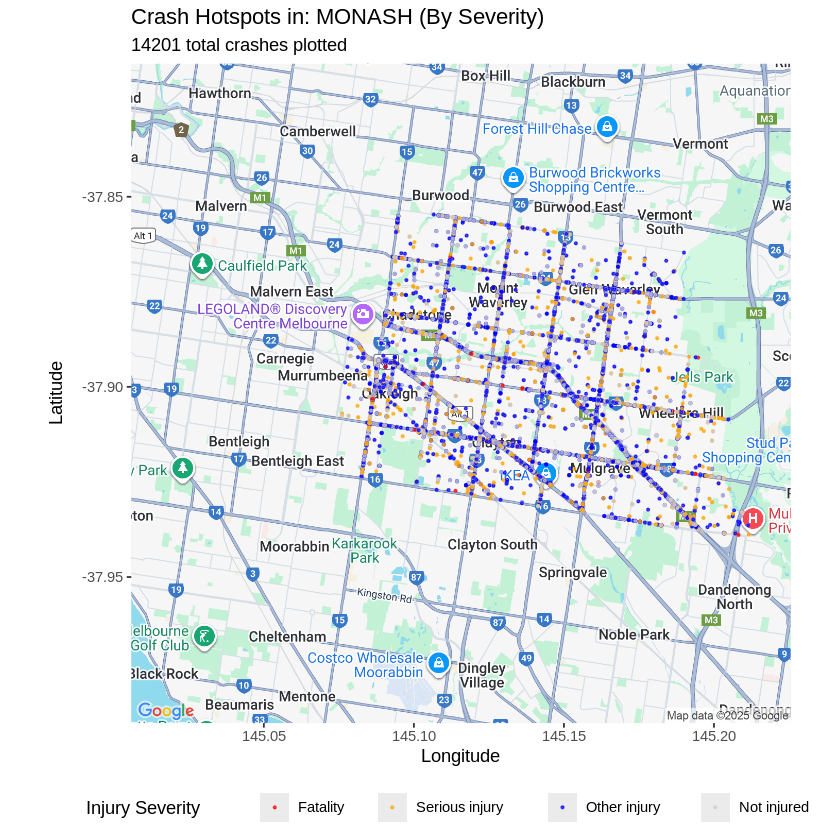

ℹ <https://maps.googleapis.com/maps/api/staticmap?center=MORELAND,%20Victoria,%20Australia&zoom=12&size=640x640&scale=2&maptype=roadmap&key=xxx-KQQ>

ℹ <https://maps.googleapis.com/maps/api/geocode/json?address=MORELAND,+Victoria,+Australia&key=xxx-KQQ>



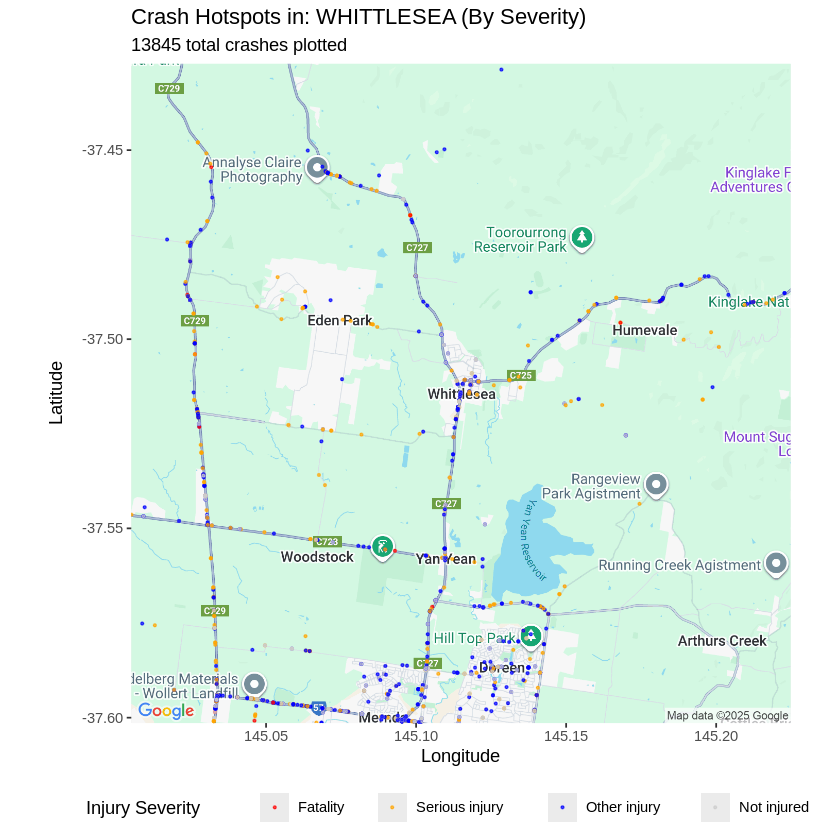

ℹ <https://maps.googleapis.com/maps/api/staticmap?center=YARRA%20RANGES,%20Victoria,%20Australia&zoom=12&size=640x640&scale=2&maptype=roadmap&key=xxx-KQQ>

ℹ <https://maps.googleapis.com/maps/api/geocode/json?address=YARRA+RANGES,+Victoria,+Australia&key=xxx-KQQ>

Warning message:
“Removed 10449 rows containing missing values or values outside the scale range
(`geom_point()`).”


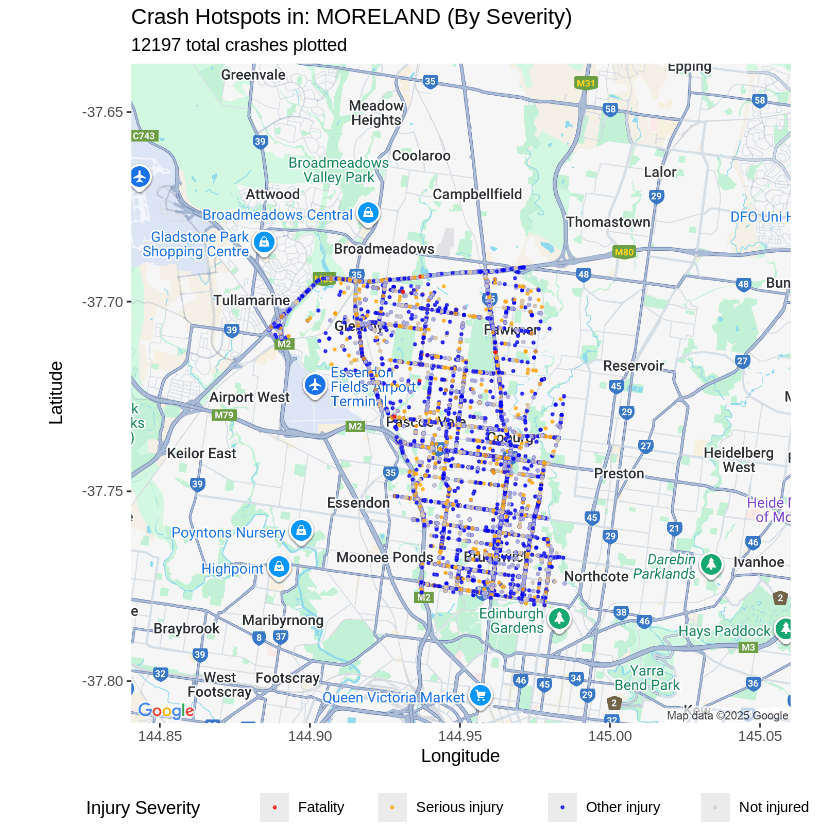

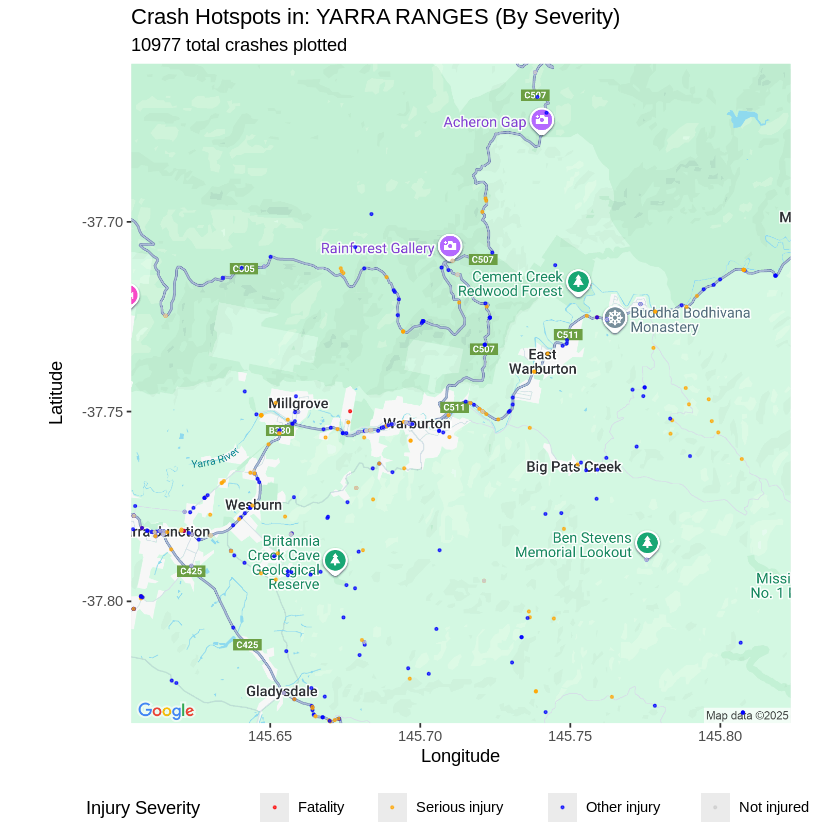

In [ ]:
#  Part B: Mapping the Top Hotspots

library(tidyverse)
library(data.table)
library(ggmap)

# 19 API requests



crash_data <- fread("vic_road_crash_data.csv")

# We need LGA_NAME, LATITUDE, and LONGITUDE

coords_df <- crash_data %>%
  select(LGA_NAME, LATITUDE, LONGITUDE) %>%
  filter(
    !is.na(LATITUDE) & !is.na(LONGITUDE) &
    LATITUDE > -39.2 & LATITUDE < -33.9 &
    LONGITUDE > 140.9 & LONGITUDE < 150.0 &
    !is.na(LGA_NAME) & LGA_NAME != ""
  )

# Targetting the Top 10 LGA's
target_lgas <- c("MELBOURNE", "CASEY","GEELONG","HUME","DANDENONG", "BRIMBANK","MONASH","WHITTLESEA","MORELAND","YARRA RANGES")

severity_levels <- c("Fatality", "Serious injury", "Other injury", "Not injured")


severity_colors <- c(
  "Fatality" = "red",
  "Serious injury" = "orange",
  "Other injury" = "blue",
  "Not injured" = "grey80"
)



for (lga_name in target_lgas) {

  # A. Get the map for the specific LGA
=
  map_center <- paste(lga_name, ", Victoria, Australia", sep="")

  lga_map <- get_googlemap(
    center = map_center,
    zoom = 12,
    maptype = "roadmap"
  )

  =
lga_coords <- master_map_df %>%
    filter(LGA_NAME == lga_name) %>%
    mutate(
      INJ_LEVEL_DESC = factor(INJ_LEVEL_DESC, levels = severity_levels)
    )

  plot <- ggmap(lga_map) +
    geom_point(
      data = lga_coords,
      aes(x = LONGITUDE, y = LATITUDE, color = INJ_LEVEL_DESC),

      size = 0.5,
      alpha = 0.7 ]
    ) +

    scale_color_manual(
      values = severity_colors,
      name = "Injury Severity",
      drop = FALSE) +

    labs(
      title = paste("Crash Hotspots in:", lga_name, "(By Severity)"),
      subtitle = paste(nrow(lga_coords), "total crashes plotted"),
      x = "Longitude",
      y = "Latitude"
    ) +
    theme(legend.position = "bottom")


  print(plot)
}

Comparing the Accident no.s across vic_road_crash_data and cleaned_person to ensure consistent format of records

In [ ]:
library(data.table)

crash_data <- fread("vic_road_crash_data.csv")
person_data <- fread("cleaned_person.csv")

cat("--- CRASH Data Key ('vic_road_crash_data.csv') ---\n")
cat("Data Type:", class(crash_data$ACCIDENT_NO), "\n")
cat("First 5 values:\n")
print(head(crash_data$ACCIDENT_NO, 5))

cat("\n--- PERSON Data Key ('cleaned_person.csv') ---\n")
cat("Data Type:", class(person_data$ACCIDENT_NO), "\n")
cat("First 5 values:\n")
print(head(person_data$ACCIDENT_NO, 5))

Warning message in fread("cleaned_person.csv"):
“Discarded single-line footer: <<T20240007258,A,A,Male,18-21,Other injury,Other injury,Driver or rider,Not known,4,Motorcycl>>”


--- CRASH Data Key ('vic_road_crash_data.csv') ---
Data Type: character 
First 5 values:
[1] "T20120011778" "T20230013207" "T20240014902" "T20160009452" "T20220001324"

--- PERSON Data Key ('cleaned_person.csv') ---
Data Type: character 
First 5 values:
[1] "T20120028483" "T20160009588" "T20190007195" "T20190010235" "T20130004323"


Fix : replacing the M,F and blank unknowns to Male, Female, Unknown

In [ ]:
library(tidyverse)
library(data.table)
library(lubridate)
library(stringr)


person_data <- fread("cleaned_person.csv") %>%
  mutate(ACCIDENT_NO = toupper(str_trim(ACCIDENT_NO)))

crash_data <- fread("vic_road_crash_data.csv") %>%
  mutate(ACCIDENT_NO = toupper(str_trim(ACCIDENT_NO)))


master_df_raw <- inner_join(
  crash_data,
  person_data,
  by = "ACCIDENT_NO"
)

master_df <- master_df_raw %>%


  mutate(
    datetime = mdy_hms(paste(ACCIDENT_DATE, ACCIDENT_TIME)),
    hour_of_day = hour(datetime)
  ) %>%


  filter(

    !is.na(datetime) &


    !is.na(INJ_LEVEL_DESC) & INJ_LEVEL_DESC != "" &


    SEX %in% c("Male", "Female", "Not known") &

    # Filter for valid age
    !is.na(AGE_GROUP) & AGE_GROUP != ""
  ) %>%


  select(
    ACCIDENT_NO,
    LGA_NAME,
    hour_of_day,
    SEX,
    AGE_GROUP,
    INJ_LEVEL_DESC
  )


cat("--- Our master dataset is ready --- \n")
print(head(master_df))

cat(paste("\nTotal rows in final master_df:", nrow(master_df), "\n"))

--- Our master dataset is ready --- 
    ACCIDENT_NO LGA_NAME hour_of_day    SEX AGE_GROUP INJ_LEVEL_DESC
         <char>   <char>       <int> <char>    <char>         <char>
1: T20120011778    CASEY          23 Female     30-39   Other injury
2: T20120011778    CASEY          23   Male     26-29    Not injured
3: T20120011778    CASEY          23 Female     18-21 Serious injury
4: T20120011778    CASEY          23   Male     30-39    Not injured
5: T20120011778    CASEY          23 Female     18-21    Not injured
6: T20120011778    CASEY          23   Male     22-25    Not injured

Total rows in final master_df: 433657 


Visualisation 3:  Severity of crashes and varying severity levels across relevant factors


Attaching package: ‘scales’


The following object is masked from ‘package:purrr’:

    discard


The following object is masked from ‘package:readr’:

    col_factor




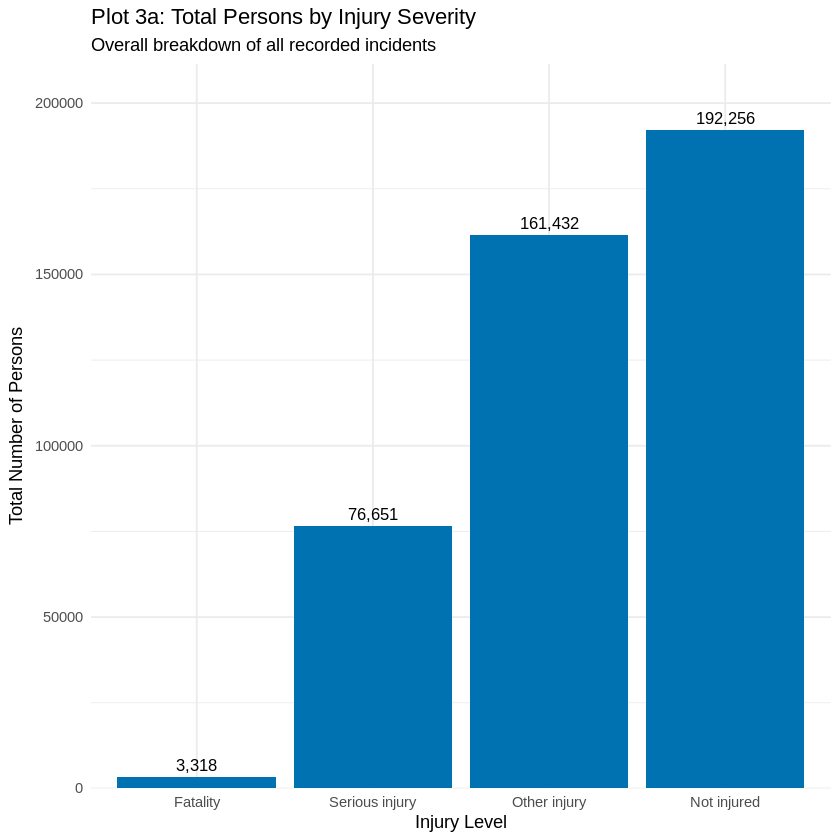

In [ ]:
library(tidyverse)
library(scales) #

# Viz 3a: Simple Severity Bar Chart



#  correct order of severity
severity_levels <- c("Fatality", "Serious injury", "Other injury", "Not injured")


severity_counts_df <- master_df %>%
  group_by(INJ_LEVEL_DESC) %>%
  summarise(count = n()) %>%
  mutate(INJ_LEVEL_DESC = factor(INJ_LEVEL_DESC, levels = severity_levels)) %>%
  filter(!is.na(INJ_LEVEL_DESC))

# Create the plot
plot_3a <- ggplot(severity_counts_df, aes(x = INJ_LEVEL_DESC, y = count)) +
  geom_col(fill = "#0072B2") +

---
  geom_text(
    aes(label = comma(count)),
    vjust = -0.5,
    color = "black",
    size = 3.5
  ) +


  # some extra space on y-axos so the labels don't cut off
  scale_y_continuous(expand = expansion(mult = c(0, 0.1))) +

  labs(
    title = "Plot 3a: Total Persons by Injury Severity",
    subtitle = "Overall breakdown of all recorded incidents",
    x = "Injury Level",
    y = "Total Number of Persons"
  ) +
  theme_minimal()

# 4. Print the plot
print(plot_3a)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘lazyeval’, ‘crosstalk’, ‘productplots’, ‘plotly’, ‘ggrepel’


Warning message in install.packages("ggmosaic"):
“installation of package ‘ggmosaic’ had non-zero exit status”


Viz 3b : Stacked Bar of Generations

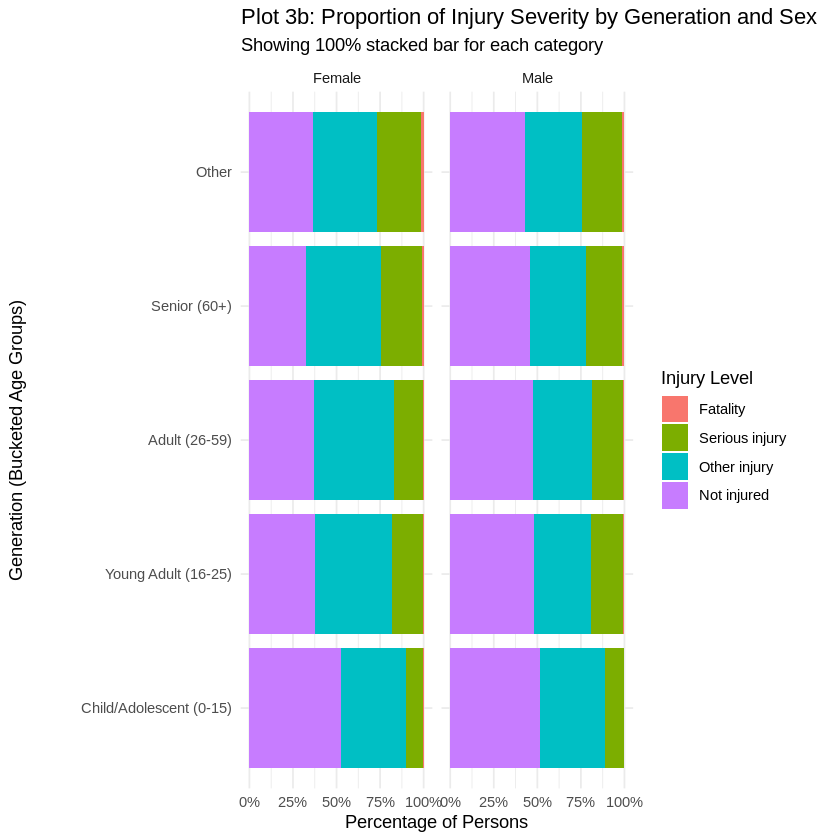

In [ ]:
library(tidyverse)
library(scales)



# Define the correct order for generation buckets
generation_levels <- c(
  "Child/Adolescent (0-15)",
  "Young Adult (16-25)",
  "Adult (26-59)",
  "Senior (60+)",
  "Other"
)

severity_levels <- c("Fatality", "Serious injury", "Other injury", "Not injured")


master_df_generations <- master_df %>%


  filter(
    SEX %in% c("Male", "Female") &
    !is.na(AGE_GROUP) & AGE_GROUP != "" & AGE_GROUP != "Not known"
  ) %>%

  # Create the new generation column
  mutate(
    generation = case_when(
      AGE_GROUP %in% c("0-4", "5-12", "13-15") ~ "Child/Adolescent (0-15)",
      AGE_GROUP %in% c("16-17", "18-21", "22-25") ~ "Young Adult (16-25)",
      AGE_GROUP %in% c("26-29", "30-39", "40-49", "50-59") ~ "Adult (26-59)",
      AGE_GROUP %in% c("60-64", "65-69", "70-74", "75+") ~ "Senior (60+)",
      TRUE ~ "Other"
    ),


    # Wehave mention the sorting order for both the generations
    generation = factor(generation, levels = generation_levels),
    INJ_LEVEL_DESC = factor(INJ_LEVEL_DESC, levels = severity_levels)

  ) %>%
  filter(!is.na(INJ_LEVEL_DESC) & !is.na(generation))

plot_3b <- ggplot(master_df_generations,
                  aes(x = generation, fill = INJ_LEVEL_DESC)) +

  geom_bar(position = "fill") +
  facet_wrap(~SEX) +
  scale_y_continuous(labels = scales::percent_format()) +
  coord_flip() + # To flip it back after sorting

  labs(
    title = "Plot 3b: Proportion of Injury Severity by Generation and Sex",
    subtitle = "Showing 100% stacked bar for each category",
    x = "Generation (Bucketed Age Groups)",
    y = "Percentage of Persons",
    fill = "Injury Level"
  ) +
  theme_minimal()


print(plot_3b)

In [ ]:
To create a severity rate % metric , 2 Injury levels : fatal and severe were joined.

Viz 3c: Time-Specific Lollipop Chart

Master DF with Date re-created. Rows: 433657 
Step 2: Creating data for Plot 3c...
Plot data 3c created. Rows: 10 


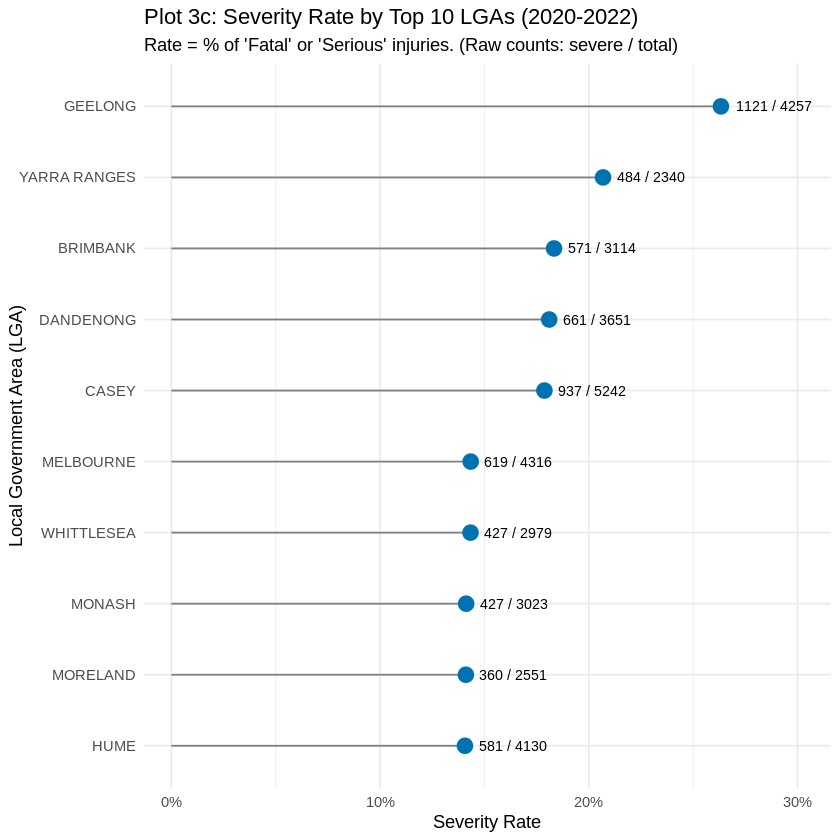

In [ ]:
library(tidyverse)
library(scales)
library(lubridate)
library(data.table)



#  Include ACCIDENT_DATE in master_df


# Load Datasets
person_data <- fread("cleaned_person.csv")
crash_data <- fread("vic_road_crash_data.csv")

# Clean Crash Data
clean_crash <- crash_data %>%
  mutate(ACCIDENT_NO = toupper(str_trim(ACCIDENT_NO))) %>%
  select(ACCIDENT_NO, LGA_NAME, ACCIDENT_DATE, ACCIDENT_TIME) %>%
  mutate(
    datetime = mdy_hms(paste(ACCIDENT_DATE, ACCIDENT_TIME)),
    hour_of_day = hour(datetime),

    accident_date_parsed = mdy(ACCIDENT_DATE)
  ) %>%
  filter(!is.na(datetime))

# Clean Person Data
clean_person <- person_data %>%
  mutate(ACCIDENT_NO = toupper(str_trim(ACCIDENT_NO))) %>%
  select(ACCIDENT_NO, SEX, AGE_GROUP, INJ_LEVEL_DESC)

# Create the Master Dataset
master_df_with_date <- inner_join(
  clean_crash,
  clean_person,
  by = "ACCIDENT_NO"
) %>%
filter(
  SEX %in% c("Male", "Female", "Not known") &
  !is.na(AGE_GROUP) & AGE_GROUP != "" &
  !is.na(INJ_LEVEL_DESC) & INJ_LEVEL_DESC != ""
)
cat("Master DF with Date re-created. Rows:", nrow(master_df_with_date), "\n")


cat("Step 2: Creating data for Plot 3c...\n")

# 1. Define our Top 10 LGA list
target_lgas <- c("MELBOURNE", "CASEY", "GEELONG", "HUME", "DANDENONG",
                 "BRIMBANK", "MONASH", "WHITTLESEA", "MORELAND", "YARRA RANGES")

# 2. Filter, Group, and Summarize
plot_data_3c <- master_df_with_date %>%

  #  Filter for a specific time period
  filter(
    accident_date_parsed >= ymd("2020-01-01") &
    accident_date_parsed <= ymd("2022-12-31")
  ) %>%


  filter(LGA_NAME %in% target_lgas) %>%

  # 3. Calculate : Severity Rate
  group_by(LGA_NAME) %>%
  summarise(
    severe_count = sum(INJ_LEVEL_DESC %in% c("Fatality", "Serious injury")),
    total_count = n(),
    severity_rate = severe_count / total_count,
    .groups = 'drop'
  ) %>%
  # Sort the LGAs by this new rate
  mutate(LGA_NAME = fct_reorder(LGA_NAME, severity_rate))

cat("Plot data 3c created. Rows:", nrow(plot_data_3c), "\n")



plot_3c_modified <- ggplot(plot_data_3c, aes(x = severity_rate, y = LGA_NAME)) +


  geom_segment(
    aes(x = 0, xend = severity_rate, y = LGA_NAME, yend = LGA_NAME),
    color = "grey50"
  ) +


  geom_point(color = "#0072B2", size = 4) +


  geom_text(
    # Label: "severe_count / total_count"
    aes(label = paste(severe_count, "/", total_count)),
    hjust = -0.2,
    size = 3,
    color = "black"
  ) +


  scale_x_continuous(
    labels = scales::percent_format(),
    # Give the labels extra space so they dont cut off
    expand = expansion(mult = c(0.05, 0.2))
  ) +

  labs(
    title = "Plot 3c: Severity Rate by Top 10 LGAs (2020-2022)",
    subtitle = "Rate = % of 'Fatal' or 'Serious' injuries. (Raw counts: severe / total)",
    x = "Severity Rate",
    y = "Local Government Area (LGA)"
  ) +
  theme_minimal()


print(plot_3c_modified)

This shows that although Melbourne had the most crashes (9701) and Geelong was 3rd with (7277); Geelong had more injuries pr crash and most of them were fatal/severe

Viz 3d: Line Chart with Peak-Time Shading

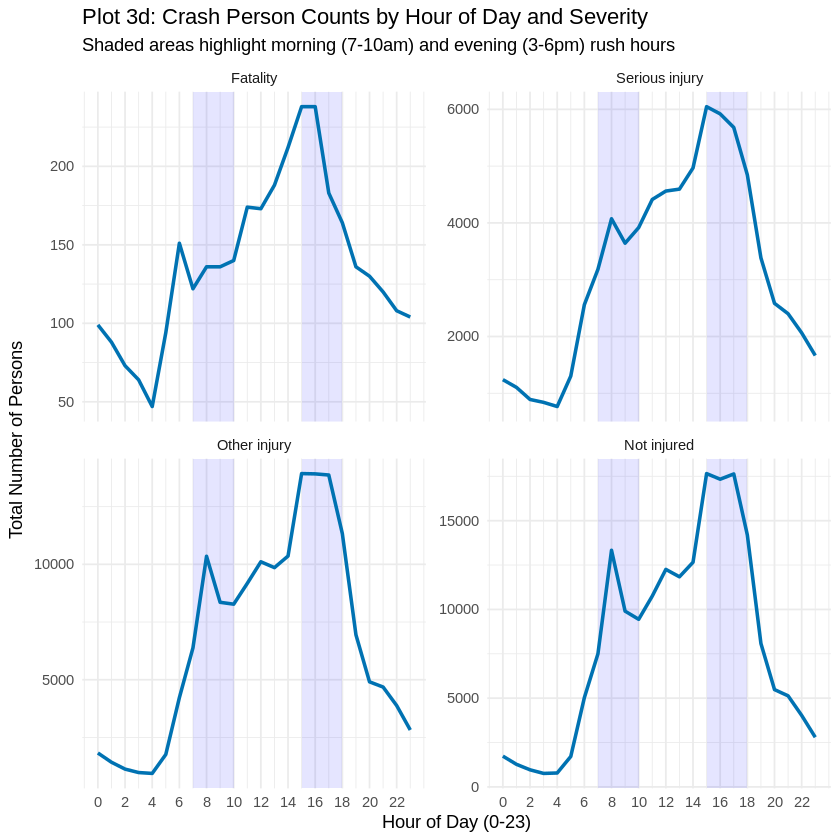

In [ ]:
library(tidyverse)
library(lubridate)



severity_levels <- c("Fatality", "Serious injury", "Other injury", "Not injured")

#  Create the data for the plot

hourly_severity_df <- master_df_with_date %>%
  mutate(
    INJ_LEVEL_DESC = factor(INJ_LEVEL_DESC, levels = severity_levels)
  ) %>%
  filter(!is.na(INJ_LEVEL_DESC)) %>%
  group_by(hour_of_day, INJ_LEVEL_DESC) %>%
  summarise(count = n(), .groups = 'drop')

# 3. Build the plot
plot_3d <- ggplot(hourly_severity_df, aes(x = hour_of_day, y = count)) +

  #
  # Adding a shaded rectangle for the Morning Rush Hour (7am- 10 am)
  annotate(
    "rect",
    xmin = 7, xmax = 10,
    ymin = -Inf, ymax = Inf,
    fill = "blue", alpha = 0.1
  ) +
  # Add a shaded rectangle for the Evening Rush Hour (3pm-6pm)
  annotate(
    "rect",
    xmin = 15, xmax = 18,
    ymin = -Inf, ymax = Inf,
    fill = "blue", alpha = 0.1
  ) +



  geom_line(color = "#0072B2", linewidth = 1) +

  # Create 4 separate charts
  facet_wrap(~ INJ_LEVEL_DESC, scales = "free_y") +

  scale_x_continuous(breaks = seq(0, 23, by = 2)) +
  labs(
    title = "Plot 3d: Crash Person Counts by Hour of Day and Severity",
    subtitle = "Shaded areas highlight morning (7-10am) and evening (3-6pm) rush hours",
    x = "Hour of Day (0-23)",
    y = "Total Number of Persons"
  ) +
  theme_minimal()


print(plot_3d)

Visualisation 4: Varying Crash severity across vehicle factors


 Plot 4a: Severity by Vehicle Type


Attaching package: ‘data.table’


The following objects are masked from ‘package:lubridate’:

    hour, isoweek, mday, minute, month, quarter, second, wday, week,
    yday, year


The following objects are masked from ‘package:dplyr’:

    between, first, last


The following object is masked from ‘package:purrr’:

    transpose




 Final V4 DF created with: 381527 


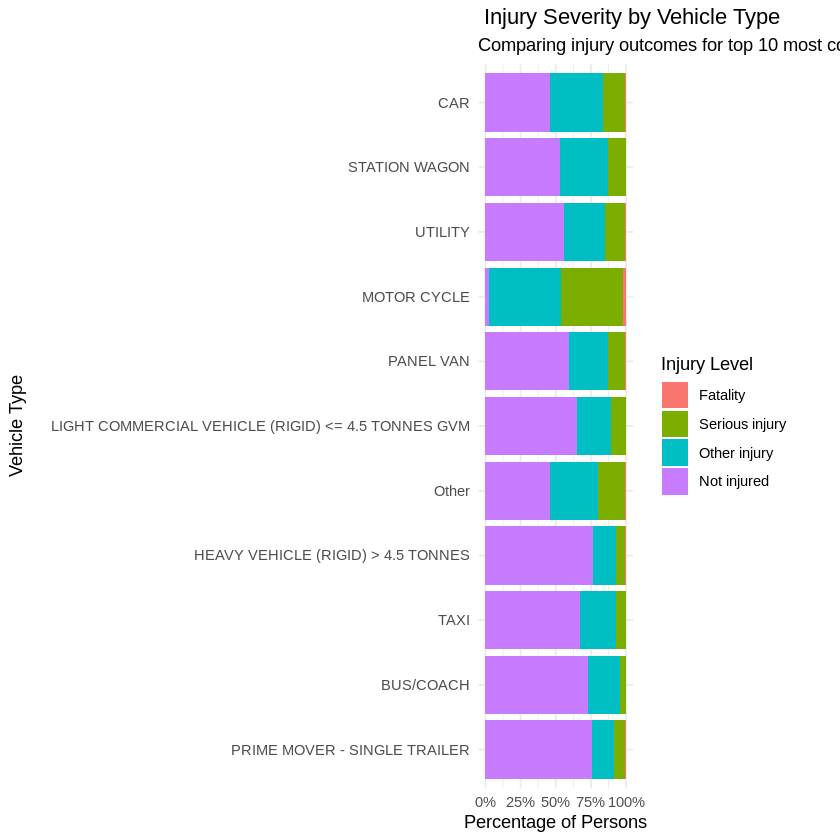

In [ ]:
library(tidyverse)
library(data.table)
library(lubridate)
library(stringr) # For str_trim and str_detect


crash_data <- fread("vic_road_crash_data.csv")
person_data <- fread("cleaned_person.csv")
vehicle_data <- fread("cleaned_vehicle.csv")


clean_crash <- crash_data %>%
  mutate(ACCIDENT_NO = toupper(str_trim(ACCIDENT_NO))) %>%
  select(ACCIDENT_NO, ACCIDENT_DATE)

clean_person <- person_data %>%
  mutate(
    ACCIDENT_NO = toupper(str_trim(ACCIDENT_NO)),
    VEHICLE_ID = toupper(str_trim(VEHICLE_ID))
  ) %>%
  select(ACCIDENT_NO, VEHICLE_ID, INJ_LEVEL_DESC) %>%
  filter(
    !is.na(INJ_LEVEL_DESC) & INJ_LEVEL_DESC != "" &
    !is.na(VEHICLE_ID) & VEHICLE_ID != ""
  )

clean_vehicle <- vehicle_data %>%
  mutate(
    ACCIDENT_NO = toupper(str_trim(ACCIDENT_NO)),
    VEHICLE_ID = toupper(str_trim(VEHICLE_ID))
  ) %>%
  select(
    ACCIDENT_NO, VEHICLE_ID, VEHICLE_YEAR_MANUF,
    VEHICLE_TYPE_DESC, VEHICLE_MAKE # We select both columns
  )

#  Perform  Three-Way Join
master_v4_raw <- inner_join(
  clean_crash,
  clean_person,
  by = "ACCIDENT_NO"
) %>%
inner_join(
  clean_vehicle,
  by = c("ACCIDENT_NO", "VEHICLE_ID")
)


master_v4_df <- master_v4_raw %>%

  # 1. Choosing vehicle age
  filter(
    VEHICLE_YEAR_MANUF >= 1950 & VEHICLE_YEAR_MANUF <= 2025 &
    !is.na(ACCIDENT_DATE)
  ) %>%
  mutate(
    ACCIDENT_DATE = mdy(ACCIDENT_DATE),
    vehicle_age = year(ACCIDENT_DATE) - VEHICLE_YEAR_MANUF
  ) %>%

  # 2. Clean VEHICLE_TYPE_DESC
  mutate(
    VEHICLE_TYPE_DESC_CLEAN = toupper(str_trim(VEHICLE_TYPE_DESC)),
    vehicle_type_clean = fct_lump_n(VEHICLE_TYPE_DESC_CLEAN, n = 10)
  ) %>%

  # 3. Clean VEHICLE_MAKE
  mutate(
    VEHICLE_MAKE_CLEAN = toupper(str_trim(VEHICLE_MAKE)),
    VEHICLE_MAKE_CLEAN = case_when(
      str_detect(VEHICLE_MAKE_CLEAN, "MERC") ~ "MERCEDES BENZ",
      str_detect(VEHICLE_MAKE_CLEAN, "TOYO") ~ "TOYOTA",
      str_detect(VEHICLE_MAKE_CLEAN, "HOLD") ~ "HOLDEN",
      str_detect(VEHICLE_MAKE_CLEAN, "FORD") ~ "FORD",
      str_detect(VEHICLE_MAKE_CLEAN, "NISS") ~ "NISSAN",
      str_detect(VEHICLE_MAKE_CLEAN, "HYUN") ~ "HYUNDAI",
      str_detect(VEHICLE_MAKE_CLEAN, "MITSU") ~ "MITSUBISHI",
      str_detect(VEHICLE_MAKE_CLEAN, "MAZDA") ~ "MAZDA",
      str_detect(VEHICLE_MAKE_CLEAN, "SUBARU") ~ "SUBARU",
      str_detect(VEHICLE_MAKE_CLEAN, "HONDA") ~ "HONDA",
      str_detect(VEHICLE_MAKE_CLEAN, "VOLKS") ~ "VOLKSWAGEN",
      TRUE ~ VEHICLE_MAKE_CLEAN
    ),
    make_clean = fct_lump_n(VEHICLE_MAKE_CLEAN, n = 10)
  ) %>%


  select(
    ACCIDENT_NO, INJ_LEVEL_DESC, vehicle_age,
    vehicle_type_clean, make_clean
  ) %>%

  filter(
    !is.na(vehicle_type_clean) & vehicle_type_clean != "" &
    !is.na(make_clean) & make_clean != ""
  )

cat(" Final V4 DF created with:", nrow(master_v4_df), "\a\n")




severity_levels <- c("Fatality", "Serious injury", "Other injury", "Not injured")


plot_4a <- master_v4_df %>%
  mutate(
    INJ_LEVEL_DESC = factor(INJ_LEVEL_DESC, levels = severity_levels)
  ) %>%
  filter(!is.na(INJ_LEVEL_DESC)) %>%

  ggplot(aes(x = fct_reorder(vehicle_type_clean, vehicle_type_clean, .fun='length'),
             fill = INJ_LEVEL_DESC)) +
  geom_bar(position = "fill") +
  scale_y_continuous(labels = scales::percent_format()) +
  coord_flip() +
  labs(
    title = " Injury Severity by Vehicle Type",
    subtitle = "Comparing injury outcomes for top 10 most common vehicle types",
    x = "Vehicle Type",
    y = "Percentage of Persons",
    fill = "Injury Level"
  ) +
  theme_minimal()


print(plot_4a)

Fix: recoding lengthy column name



Attaching package: ‘scales’


The following object is masked from ‘package:purrr’:

    discard


The following object is masked from ‘package:readr’:

    col_factor




Step 1 Complete. 'master_v4_df' is ready.
Step 2: Building Plot 4a...


Warning message:
“There was 1 warning in `mutate()`.
ℹ In argument: `vehicle_type_clean = fct_recode(vehicle_type_clean, `LCV (Rigid
  <=4.5 Ton)` = "LIGHT COMMERCIAL VEHICLE (RIGID <= 4.5 TONNES GVM)")`.
Caused by warning:
! Unknown levels in `f`: LIGHT COMMERCIAL VEHICLE (RIGID <= 4.5 TONNES GVM)”


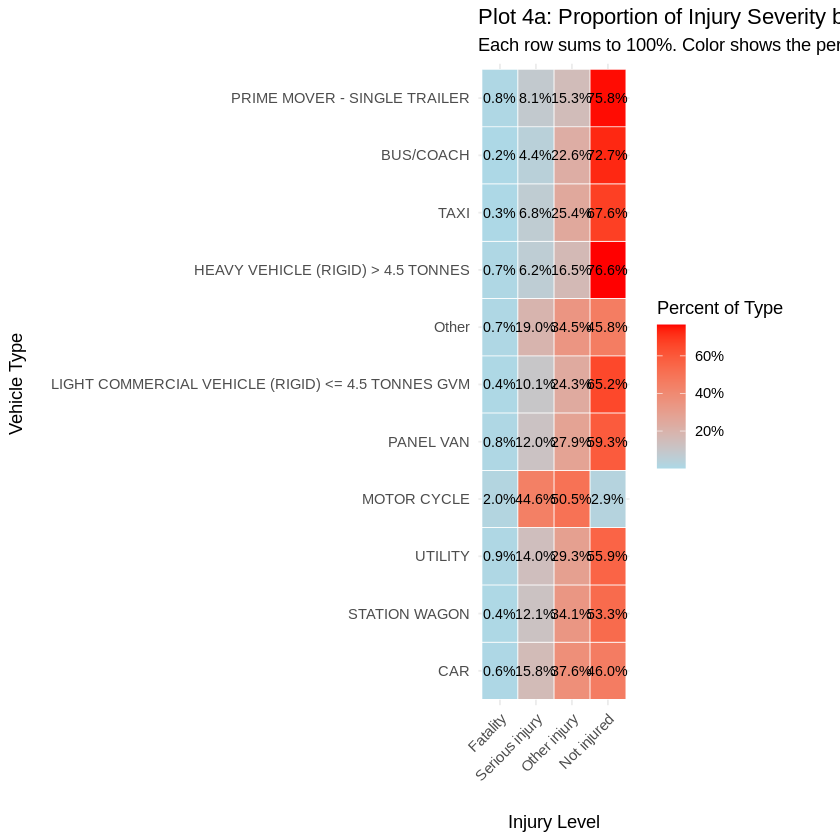

In [ ]:
library(tidyverse)
library(data.table)
library(lubridate)
library(stringr)
library(scales)
library(RColorBrewer)



crash_data <- fread("vic_road_crash_data.csv")
person_data <- fread("cleaned_person.csv")
vehicle_data <- fread("cleaned_vehicle.csv")

clean_crash <- crash_data %>%
  mutate(ACCIDENT_NO = toupper(str_trim(ACCIDENT_NO))) %>%
  select(ACCIDENT_NO, ACCIDENT_DATE)

clean_person <- person_data %>%
  mutate(
    ACCIDENT_NO = toupper(str_trim(ACCIDENT_NO)),
    VEHICLE_ID = toupper(str_trim(VEHICLE_ID))
  ) %>%
  select(ACCIDENT_NO, VEHICLE_ID, INJ_LEVEL_DESC) %>%
  filter(!is.na(INJ_LEVEL_DESC) & INJ_LEVEL_DESC != "")

clean_vehicle <- vehicle_data %>%
  mutate(
    ACCIDENT_NO = toupper(str_trim(ACCIDENT_NO)),
    VEHICLE_ID = toupper(str_trim(VEHICLE_ID))
  ) %>%
  select(ACCIDENT_NO, VEHICLE_ID, VEHICLE_YEAR_MANUF, VEHICLE_TYPE_DESC, VEHICLE_MAKE)

master_v4_raw <- inner_join(clean_crash, clean_person, by = "ACCIDENT_NO") %>%
                 inner_join(clean_vehicle, by = c("ACCIDENT_NO", "VEHICLE_ID"))

master_v4_df <- master_v4_raw %>%
  filter(VEHICLE_YEAR_MANUF >= 1980 & VEHICLE_YEAR_MANUF <= 2024 & !is.na(ACCIDENT_DATE)) %>%
  mutate(
    ACCIDENT_DATE = mdy(ACCIDENT_DATE),
    vehicle_age = year(ACCIDENT_DATE) - VEHICLE_YEAR_MANUF,
    vehicle_type_clean = fct_lump_n(toupper(str_trim(VEHICLE_TYPE_DESC)), n = 10),
    VEHICLE_MAKE_CLEAN = toupper(str_trim(VEHICLE_MAKE)),
    VEHICLE_MAKE_CLEAN = case_when(
      str_detect(VEHICLE_MAKE_CLEAN, "MERC") ~ "MERCEDES BENZ",
      str_detect(VEHICLE_MAKE_CLEAN, "TOYO") ~ "TOYOTA",
      str_detect(VEHICLE_MAKE_CLEAN, "HOLD") ~ "HOLDEN",
      str_detect(VEHICLE_MAKE_CLEAN, "FORD") ~ "FORD",
      TRUE ~ VEHICLE_MAKE_CLEAN
    ),
    make_clean = fct_lump_n(VEHICLE_MAKE_CLEAN, n = 10)
  ) %>%
  select(ACCIDENT_NO, INJ_LEVEL_DESC, vehicle_age, vehicle_type_clean, make_clean) %>%
  filter(!is.na(vehicle_type_clean) & vehicle_type_clean != "" & !is.na(make_clean))
cat("Step 1 Complete. 'master_v4_df' is ready.\n")



cat("Step 2: Building Plot 4a...\n")
severity_levels <- c("Fatality", "Serious injury", "Other injury", "Not injured")

plot_data_4a <- master_v4_df %>%

  # recode the messy label
  mutate(
    vehicle_type_clean = fct_recode(
      vehicle_type_clean, # This now correctly refers to the column
      "LCV (Rigid <=4.5 Ton)" = "LIGHT COMMERCIAL VEHICLE (RIGID <= 4.5 TONNES GVM)"
    )
  ) %>%



  group_by(vehicle_type_clean, INJ_LEVEL_DESC) %>%
  summarise(count = n(), .groups = 'drop') %>%

  group_by(vehicle_type_clean) %>%
  mutate(
    total_in_type = sum(count),
    percent_of_type = count / total_in_type
  ) %>%
  ungroup() %>%

  mutate(
    INJ_LEVEL_DESC = factor(INJ_LEVEL_DESC, levels = severity_levels),

    vehicle_type_clean = fct_reorder(vehicle_type_clean, total_in_type, .desc = TRUE)
  )


plot_4a <- ggplot(
    plot_data_4a,
    aes(x = INJ_LEVEL_DESC, y = vehicle_type_clean, fill = percent_of_type)
  ) +
  geom_tile(color = "white") +
  geom_text(aes(label = scales::percent(percent_of_type, accuracy = 0.1)), size = 3) +
  scale_fill_gradient(low = "lightblue", high = "red", labels = scales::percent) +
  labs(
    title = "Plot 4a: Proportion of Injury Severity by Vehicle Type",
    subtitle = "Each row sums to 100%. Color shows the percentage in each cell.",
    x = "Injury Level",
    y = "Vehicle Type",
    fill = "Percent of Type"
  ) +
  theme_minimal() +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    legend.position = "right"
  )

# Print the plot
print(plot_4a)

Step 1: Loading all three CSVs...
Step 2: Cleaning and preparing data...
Step 3: Performing three-way join...
Step 4: Engineering new features...
Step 4 Complete. 'master_v4_df' is ready. Rows: 380582 
Step 5: Building Plot 4a (Heatmap)...


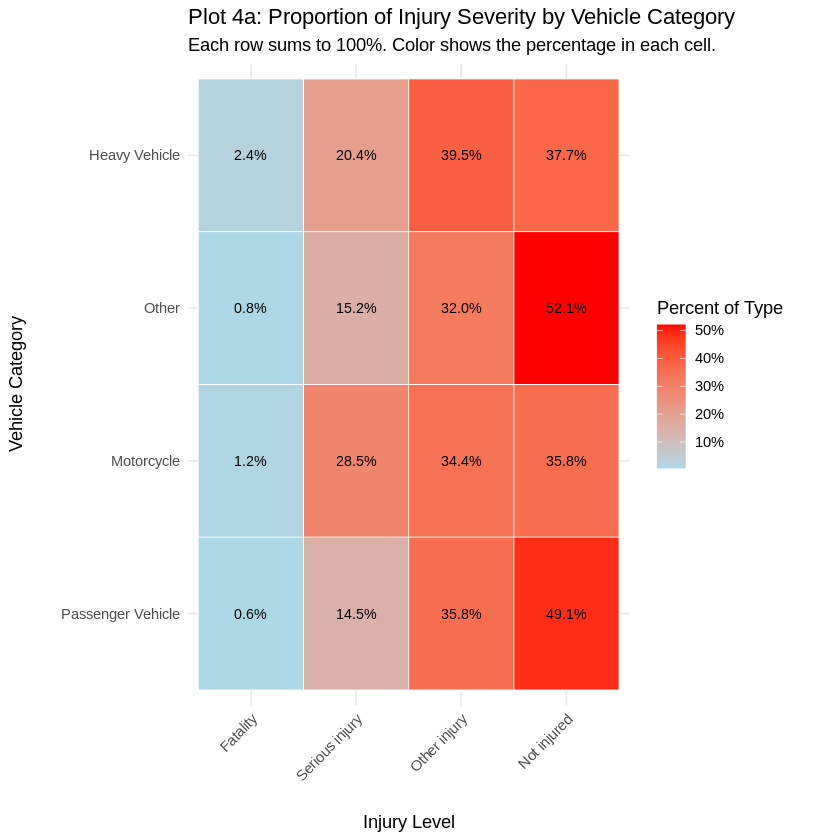

In [ ]:
library(tidyverse)
library(data.table)
library(lubridate)
library(stringr)
library(scales)
library(RColorBrewer)

cat("Step 1: Loading all three CSVs...\n")
crash_data <- fread("vic_road_crash_data.csv")
person_data <- fread("cleaned_person.csv")
vehicle_data <- fread("cleaned_vehicle.csv")


cat("Step 2: Cleaning and preparing data...\n")

# Clean Crash Data
clean_crash <- crash_data %>%
  mutate(ACCIDENT_NO = toupper(str_trim(ACCIDENT_NO))) %>%
  select(
    ACCIDENT_NO, ACCIDENT_DATE,

    MOTORCYCLE, PASSENGERVEHICLE, HEAVYVEHICLE
  )

# Clean Person Data
clean_person <- person_data %>%
  mutate(
    ACCIDENT_NO = toupper(str_trim(ACCIDENT_NO)),
    VEHICLE_ID = toupper(str_trim(VEHICLE_ID))
  ) %>%
  select(ACCIDENT_NO, VEHICLE_ID, INJ_LEVEL_DESC) %>%
  filter(!is.na(INJ_LEVEL_DESC) & INJ_LEVEL_DESC != "")

# Clean Vehicle Data
clean_vehicle <- vehicle_data %>%
  mutate(
    ACCIDENT_NO = toupper(str_trim(ACCIDENT_NO)),
    VEHICLE_ID = toupper(str_trim(VEHICLE_ID))
  ) %>%
  select(ACCIDENT_NO, VEHICLE_ID, VEHICLE_YEAR_MANUF)


cat("Step 3: Performing three-way join...\n")
master_v4_raw <- inner_join(clean_crash, clean_person, by = "ACCIDENT_NO") %>%
                 inner_join(clean_vehicle, by = c("ACCIDENT_NO", "VEHICLE_ID"))

#  Feature Engineering
cat("Step 4: Engineering new features...\n")
master_v4_df <- master_v4_raw %>%

  # 1. Create vehicle_age
  filter(VEHICLE_YEAR_MANUF >= 1980 & VEHICLE_YEAR_MANUF <= 2024 & !is.na(ACCIDENT_DATE)) %>%
  mutate(
    ACCIDENT_DATE = mdy(ACCIDENT_DATE),
    vehicle_age = year(ACCIDENT_DATE) - VEHICLE_YEAR_MANUF
  ) %>%

  # 2. Create new 'vehicle_category'
  mutate(
    vehicle_category = case_when(
      MOTORCYCLE > 0 ~ "Motorcycle",
      PASSENGERVEHICLE > 0 ~ "Passenger Vehicle",
      HEAVYVEHICLE > 0 ~ "Heavy Vehicle",
      TRUE ~ "Other" # This will catch bicycles, etc.
    )
  ) %>%

  # 3. Final selection
  select(
    ACCIDENT_NO, INJ_LEVEL_DESC, vehicle_age, vehicle_category
  ) %>%

  filter(!is.na(vehicle_category))

cat("Step 4 Complete. 'master_v4_df' is ready. Rows:", nrow(master_v4_df), "\n")



cat("Step 5: Building Plot 4a (Heatmap)...\n")
severity_levels <- c("Fatality", "Serious injury", "Other injury", "Not injured")


plot_data_4a <- master_v4_df %>%


  group_by(vehicle_category, INJ_LEVEL_DESC) %>%
  summarise(count = n(), .groups = 'drop') %>%

  group_by(vehicle_category) %>%
  mutate(
    total_in_type = sum(count),
    percent_of_type = count / total_in_type
  ) %>%
  ungroup() %>%

  mutate(
    INJ_LEVEL_DESC = factor(INJ_LEVEL_DESC, levels = severity_levels),

    vehicle_category = fct_reorder(vehicle_category, total_in_type, .desc = TRUE)
  )


plot_4a <- ggplot(
    plot_data_4a,
    aes(x = INJ_LEVEL_DESC, y = vehicle_category, fill = percent_of_type)
  ) +
  geom_tile(color = "white") +
  geom_text(aes(label = scales::percent(percent_of_type, accuracy = 0.1)), size = 3) +
  scale_fill_gradient(low = "lightblue", high = "red", labels = scales::percent) +
  labs(
    title = "Plot 4a: Proportion of Injury Severity by Vehicle Category",
    subtitle = "Each row sums to 100%. Color shows the percentage in each cell.",
    x = "Injury Level",
    y = "Vehicle Category",
    fill = "Percent of Type"
  ) +
  theme_minimal() +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    legend.position = "right"
  )

# Print the plot
print(plot_4a)

Viz 4b: Violin Plot of Vehicle Age vs. Severity

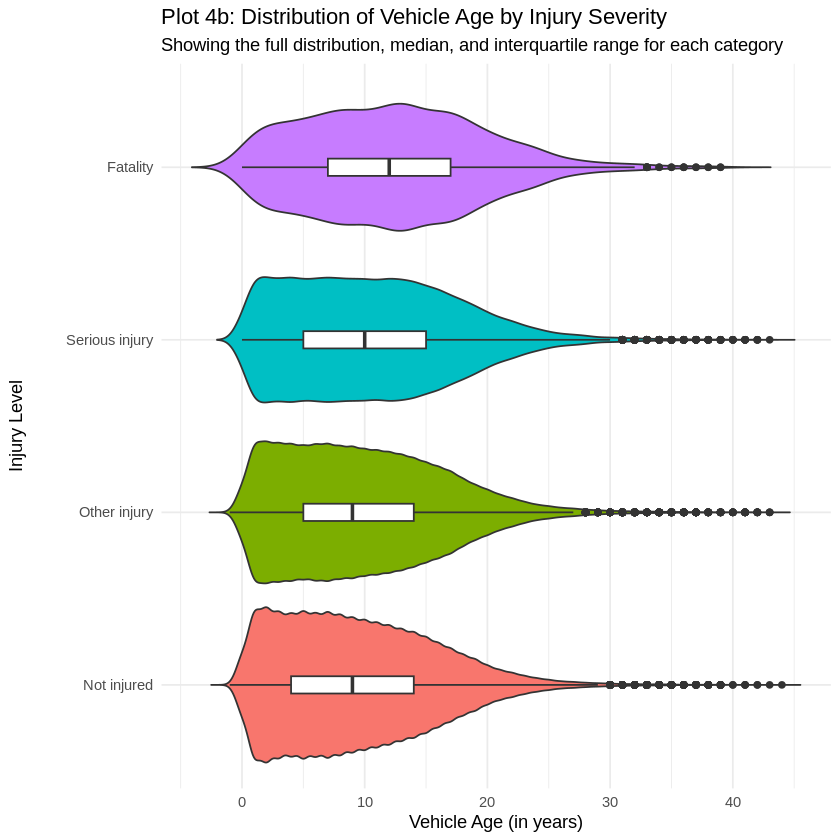

In [ ]:
library(tidyverse)
library(lubridate)





#  Define the correct order of severity
severity_levels <- c("Not injured", "Other injury", "Serious injury", "Fatality")

plot_data_4b <- master_v4_df %>%
  mutate(
    # Reorder severity from least to most severe
    INJ_LEVEL_DESC = factor(INJ_LEVEL_DESC, levels = severity_levels)
  ) %>%
  filter(!is.na(INJ_LEVEL_DESC))


plot_4b <- ggplot(plot_data_4b, aes(x = INJ_LEVEL_DESC, y = vehicle_age, fill = INJ_LEVEL_DESC)) +


  geom_violin(trim = FALSE) +


  geom_boxplot(width = 0.1, fill = "white") +


  coord_flip() +

  labs(
    title = "Plot 4b: Distribution of Vehicle Age by Injury Severity",
    subtitle = "Showing the full distribution, median, and interquartile range for each category",
    x = "Injury Level",
    y = "Vehicle Age (in years)"
  ) +
  theme_minimal() +
  theme(legend.position = "none")

print(plot_4b)


Viz 4b: Age vs. Severity, Faceted by Vehicle Category, created earlier

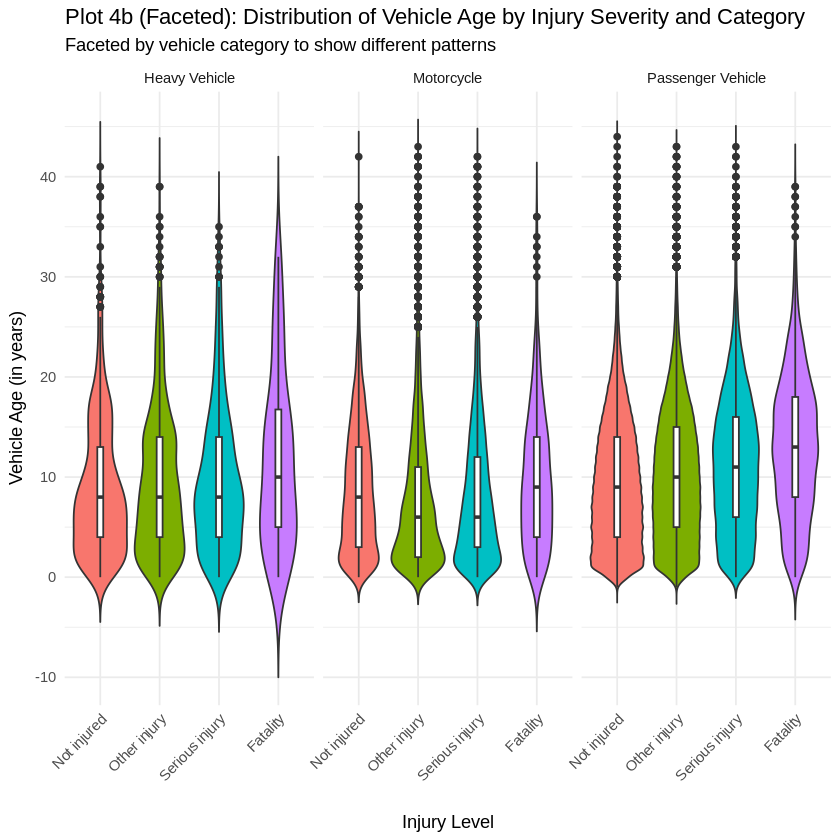

In [ ]:
library(tidyverse)
library(lubridate)




severity_levels <- c("Not injured", "Other injury", "Serious injury", "Fatality")


plot_data_4b_facet <- master_v4_df %>%
  mutate(

    INJ_LEVEL_DESC = factor(INJ_LEVEL_DESC, levels = severity_levels)
  ) %>%

  filter(vehicle_category != "Other") %>%
  filter(!is.na(INJ_LEVEL_DESC))


plot_4b_facet <- ggplot(plot_data_4b_facet,
                   aes(x = INJ_LEVEL_DESC, y = vehicle_age, fill = INJ_LEVEL_DESC)) +

  geom_violin(trim = FALSE) +
  geom_boxplot(width = 0.1, fill = "white") +

  facet_wrap(~ vehicle_category) +


  labs(
    title = "Plot 4b (Faceted): Distribution of Vehicle Age by Injury Severity and Category",
    subtitle = "Faceted by vehicle category to show different patterns",
    x = "Injury Level",
    y = "Vehicle Age (in years)"
  ) +
  theme_minimal() +
  theme(
    legend.position = "none",

    axis.text.x = element_text(angle = 45, hjust = 1)
  )


print(plot_4b_facet)

Finding top 30 raw make entries

In [ ]:
library(tidyverse)
library(data.table)
library(stringr)



vehicle_data <- fread("cleaned_vehicle.csv")


top_30_makes <- vehicle_data %>%


  mutate(MAKE_RAW = toupper(str_trim(VEHICLE_MAKE))) %>%


  count(MAKE_RAW, sort = TRUE) %>%


  head(30)


cat("--- Top 30 Raw 'VEHICLE_MAKE' Entries ---\n")
print(top_30_makes)

--- Top 30 Raw 'VEHICLE_MAKE' Entries ---
           MAKE_RAW     n
             <char> <int>
 1:          TOYOTA 56358
 2:          HOLDEN 41184
 3:            FORD 33893
 4:           MAZDA 20137
 5:           HONDA 17607
 6:          NISSAN 16546
 7:          MITSUB 15978
 8:                 15067
 9:         HYUNDAI 13971
10:            UNKN  9764
11:      VOLKSWAGEN  8860
12:   MERCEDES-BENZ  7215
13:          SUBARU  6981
14:          SUZUKI  6978
15:             KIA  6462
16:           B M W  6111
17:          YAMAHA  4044
18:           ISUZU  3458
19:            AUDI  2675
20:           VOLVO  2628
21: HARLEY DAVIDSON  2548
22:        KAWASAKI  2506
23:            JEEP  2368
24:        KENWORTH  1708
25:           K T M  1707
26:           LEXUS  1455
27:            HINO  1450
28:            PEUG  1402
29:         RENAULT  1401
30:      LAND ROVER  1268
           MAKE_RAW     n


Viz 4c: Crash severity vs make

Step 1: Re-building the final master_v4_df...


Warning message:
“There was 1 warning in `mutate()`.
ℹ In argument: `make_clean = fct_recode(make_clean, UNKNOWN = "UNKNOWN")`.
Caused by warning:
! Unknown levels in `f`: UNKNOWN”


Step 1 Complete. Final 'master_v4_df' is ready.
Step 2: Building Plot 4c (Treemap)...


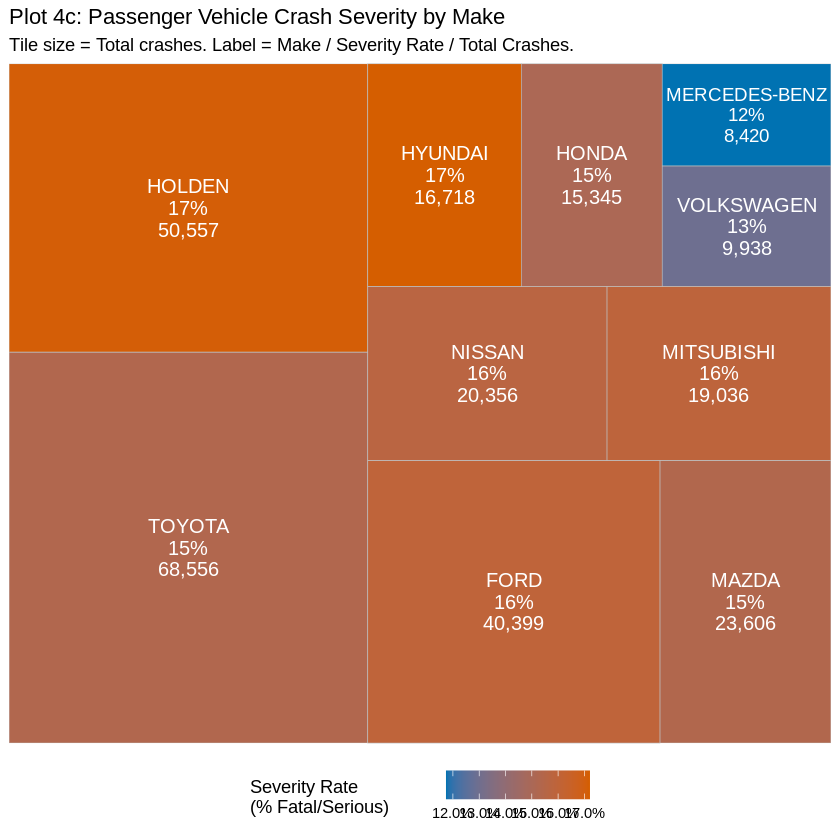

In [ ]:

library(tidyverse)
library(data.table)
library(lubridate)
library(stringr)
library(treemapify)
library(scales)


cat("Step 1: Re-building the final master_v4_df...\n")
crash_data <- fread("vic_road_crash_data.csv")
person_data <- fread("cleaned_person.csv")
vehicle_data <- fread("cleaned_vehicle.csv")


clean_crash <- crash_data %>%
  mutate(ACCIDENT_NO = toupper(str_trim(ACCIDENT_NO))) %>%
  select(
    ACCIDENT_NO, ACCIDENT_DATE,
    MOTORCYCLE, PASSENGERVEHICLE, HEAVYVEHICLE
  )

clean_person <- person_data %>%
  mutate(
    ACCIDENT_NO = toupper(str_trim(ACCIDENT_NO)),
    VEHICLE_ID = toupper(str_trim(VEHICLE_ID))
  ) %>%
  select(ACCIDENT_NO, VEHICLE_ID, INJ_LEVEL_DESC) %>%
  filter(!is.na(INJ_LEVEL_DESC) & INJ_LEVEL_DESC != "")


clean_vehicle <- vehicle_data %>%
  mutate(
    ACCIDENT_NO = toupper(str_trim(ACCIDENT_NO)),
    VEHICLE_ID = toupper(str_trim(VEHICLE_ID))
  ) %>%
  select(ACCIDENT_NO, VEHICLE_ID, VEHICLE_YEAR_MANUF, VEHICLE_MAKE)


master_v4_raw <- inner_join(clean_crash, clean_person, by = "ACCIDENT_NO") %>%
                 inner_join(clean_vehicle, by = c("ACCIDENT_NO", "VEHICLE_ID"))


master_v4_df <- master_v4_raw %>%
  filter(VEHICLE_YEAR_MANUF >= 1980 & VEHICLE_YEAR_MANUF <= 2024 & !is.na(ACCIDENT_DATE)) %>%
  mutate(
    ACCIDENT_DATE = mdy(ACCIDENT_DATE),
    vehicle_age = year(ACCIDENT_DATE) - VEHICLE_YEAR_MANUF,
    vehicle_category = case_when(
      MOTORCYCLE > 0 ~ "Motorcycle",
      PASSENGERVEHICLE > 0 ~ "Passenger Vehicle",
      HEAVYVEHICLE > 0 ~ "Heavy Vehicle",
      TRUE ~ "Other"
    ),
    VEHICLE_MAKE_CLEAN = toupper(str_trim(VEHICLE_MAKE)),
    VEHICLE_MAKE_CLEAN = case_when(
      VEHICLE_MAKE_CLEAN == "MITSUB" ~ "MITSUBISHI",
      VEHICLE_MAKE_CLEAN == "B M W" ~ "BMW",
      VEHICLE_MAKE_CLEAN == "PEUG" ~ "PEUGEOT",
      VEHICLE_MAKE_CLEAN == "UNKN" ~ "UNKNOWN",
      VEHICLE_MAKE_CLEAN == "" ~ "UNKNOWN",
      TRUE ~ VEHICLE_MAKE_CLEAN
    ),
    make_clean = fct_lump_n(
      VEHICLE_MAKE_CLEAN,
      n = 10,
      other_level = "Other",
      ties.method = "first"
    ),
    make_clean = fct_recode(make_clean, "UNKNOWN" = "UNKNOWN")
  ) %>%
  select(
    ACCIDENT_NO, INJ_LEVEL_DESC, vehicle_age,
    vehicle_category, make_clean
  ) %>%
  filter(!is.na(vehicle_category) & !is.na(make_clean))

cat("Step 1 Complete. Final 'master_v4_df' is ready.\n")


cat("Step 2: Building Plot 4c (Treemap)...\n")

plot_data_4c <- master_v4_df %>%

  filter(vehicle_category == "Passenger Vehicle") %>%

  filter(make_clean != "UNKNOWN" & make_clean != "Other") %>%

  group_by(make_clean) %>%
  summarise(
    severe_count = sum(INJ_LEVEL_DESC %in% c("Fatality", "Serious injury")),
    total_count = n(),
    severity_rate = severe_count / total_count,
    .groups = 'drop'
  )


plot_4c <- ggplot(
    plot_data_4c,
    aes(
      area = total_count,
      fill = severity_rate,
      label = make_clean
    )
  ) +

  geom_treemap() +


  geom_treemap_text(
    aes(label = paste(
      make_clean,
      scales::percent(severity_rate, 1),
      scales::comma(total_count),
      sep = "\n")
    ),
    color = "white",
    place = "centre",
    size = 12
  ) +

  scale_fill_gradient(
    low = "#0072B2", high = "#D55E00",
    labels = scales::percent,
    name = "Severity Rate\n(% Fatal/Serious)"
  ) +

  labs(
    title = "Plot 4c: Passenger Vehicle Crash Severity by Make",
    subtitle = "Tile size = Total crashes. Label = Make / Severity Rate / Total Crashes."
  ) +
  theme(legend.position = "bottom")

# 3. Print the plot
print(plot_4c)

Visualisation 5: Crash Severity Rate by Light and Road Conditions

Step 1: Building master_df for Viz 5...
Step 1 Complete. 'master_df_viz5' is ready. Rows: 433657 
Step 2: Creating data for Plot 5...
Step 2 Complete. Plot data is ready. Rows: 29 
Step 3: Building Plot 5 (Heatmap)...


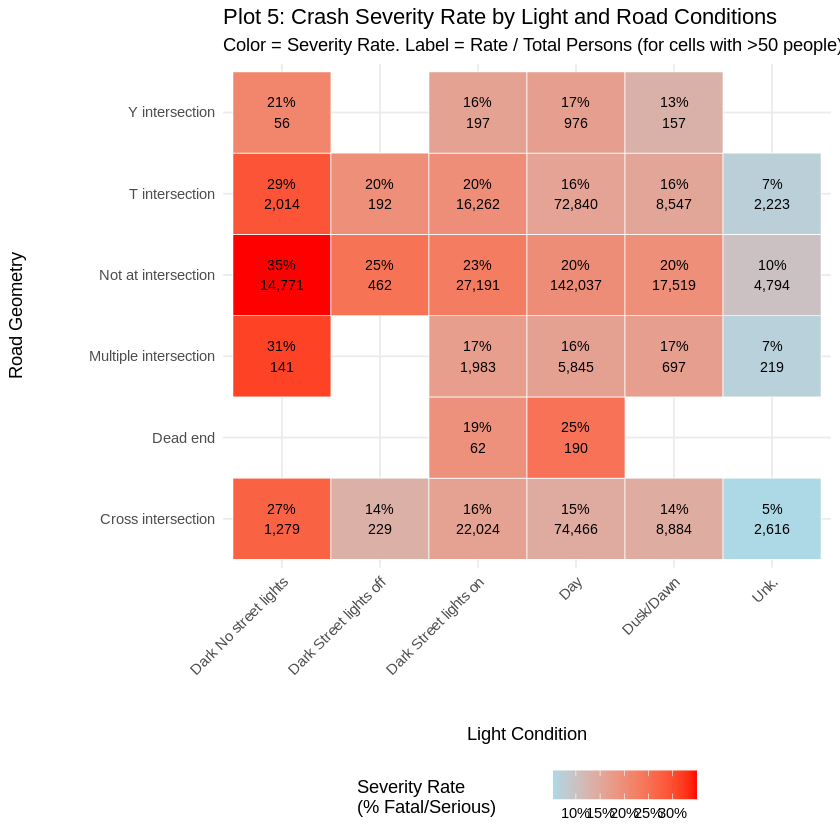

In [ ]:
library(tidyverse)
library(data.table)
library(stringr)
library(scales)
library(RColorBrewer)


cat("Step 1: Building master_df for Viz 5...\n")

# Load Datasets
person_data <- fread("cleaned_person.csv")
crash_data <- fread("vic_road_crash_data.csv")


clean_crash <- crash_data %>%
  mutate(ACCIDENT_NO = toupper(str_trim(ACCIDENT_NO))) %>%
  select(
    ACCIDENT_NO,
    LIGHT_CONDITION,
    ROAD_GEOMETRY
  )


clean_person <- person_data %>%
  mutate(ACCIDENT_NO = toupper(str_trim(ACCIDENT_NO))) %>%
  select(ACCIDENT_NO, INJ_LEVEL_DESC, INJ_LEVEL)


master_df_viz5 <- inner_join(
  clean_crash,
  clean_person,
  by = "ACCIDENT_NO"
)

cat("Step 1 Complete. 'master_df_viz5' is ready. Rows:", nrow(master_df_viz5), "\n")

cat("Step 2: Creating data for Plot 5...\n")

#  Clean and lump the categories

plot_data_5 <- master_df_viz5 %>%

  # Cleaning Unknown
  filter(
    !is.na(LIGHT_CONDITION) & LIGHT_CONDITION != "" &
    !is.na(ROAD_GEOMETRY) & ROAD_GEOMETRY != "" &
    !str_detect(toupper(LIGHT_CONDITION), "UNKNOWN") &
    !str_detect(toupper(ROAD_GEOMETRY), "UNKNOWN") &
    !is.na(INJ_LEVEL) & INJ_LEVEL != ""
  ) %>%

  # Lump into Top 6 for a clean plot
  mutate(
    light_condition_clean = fct_lump_n(LIGHT_CONDITION, n = 6),
    road_geometry_clean = fct_lump_n(ROAD_GEOMETRY, n = 6)
  ) %>%

  # Calculate Severity Rate for each combination
  group_by(light_condition_clean, road_geometry_clean) %>%
  summarise(
    severe_count = sum(INJ_LEVEL_DESC %in% c("Fatality", "Serious injury")),
    total_count = n(),
    severity_rate = severe_count / total_count,
    .groups = 'drop'
  ) %>%

  # Filter out combinations with very few crashes
  filter(total_count > 50)

cat("Step 2 Complete. Plot data is ready. Rows:", nrow(plot_data_5), "\n")

cat("Step 3: Building Plot 5 (Heatmap)...\n")

plot_5 <- ggplot(
    plot_data_5,
    aes(x = light_condition_clean, y = road_geometry_clean, fill = severity_rate)
  ) +

  geom_tile(color = "white") +


  geom_text(
    aes(label = paste(
      scales::percent(severity_rate, 1),
      scales::comma(total_count),
      sep = "\n")
    ),
    size = 3, color = "black"
  ) +


  scale_fill_gradient(
    low = "lightblue", high = "red",
    labels = scales::percent,
    name = "Severity Rate\n(% Fatal/Serious)"
  ) +

  labs(
    title = "Plot 5: Crash Severity Rate by Light and Road Conditions",
    subtitle = "Color = Severity Rate. Label = Rate / Total Persons (for cells with >50 people).",
    x = "Light Condition",
    y = "Road Geometry"
  ) +
  theme_minimal() +

  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    legend.position = "bottom"
  )

print(plot_5)